# Homework 3: Unsupervised Learning, Dimensionality Reduction, and Anomaly Detection

## 1. Dataset Selection

* **Dataset Chosen:** Room Impulse Response (RIR) Acoustic Metadata Corpus (`rirmega`).
* **Source & Origin:** Real-world measured and physics-simulated acoustic enclosures hosted on Hugging Face (`mandipgoswami/rirmega`). The dataset contains 1,000 observations and 10 extracted continuous physical and geometric features, easily satisfying the assignment requirement of at least 1,000 rows and 8 features.
* **Why it was collected & Who collected it:** Collected by acoustic signal processing researchers to benchmark how 3D physical enclosures alter sound propagation through boundary reflections, frequency-dependent absorption, and spatial geometry.
* **What each feature represents:** We extract 10 continuous numerical descriptors spanning room acoustics and 3D geometry:
  1. `rt60`: Reverberation Time ($RT_{60}$, in seconds) — time required for sound energy to decay by 60 dB.
  2. `drr_db`: Direct-to-Reverberant Ratio ($DRR$, in dB) — energy ratio of direct arrival path vs. reflected room energy.
  3. `c50_db`: Speech Clarity Index ($C_{50}$, in dB) — early-to-late sound energy ratio using a 50 ms integration window.
  4. `c80_db`: Music Clarity Index ($C_{80}$, in dB) — early-to-late sound energy ratio using an 80 ms integration window.
  5. `volume`: Total Room Enclosure Volume ($V = L \times W \times H$, in $\text{m}^3$).
  6. `surface_area`: Total Reflective Boundary Surface Area ($S = 2(LW + LH + WH)$, in $\text{m}^2$).
  7. `aspect_ratio`: Room Geometric Elongation Ratio ($\max(L,W,H) / \min(L,W,H)$), distinguishing shoebox rooms from elongated corridors.
  8. `src_mic_dist`: Euclidean 3D Source-to-Microphone Distance ($\Vert{}\mathbf{r}_{\text{src}} - \mathbf{r}_{\text{mic}}\Vert{}_2$, in meters).
  9. `absorption`: Mean Broadband Boundary Absorption Coefficient ($\bar{\alpha}$).
  10. `abs_125hz`: Low-Frequency (125 Hz Octave Band) Boundary Absorption Coefficient ($\alpha_{125}$).
* **Limitations or biases:** Shoebox geometric assumptions and extreme near-field or boundary microphone placements can introduce simulation artifacts and heavy-tailed distributions in highly coupled or elongated spaces (such as corridors and warehouses).
* **Anomaly Status:** There is no pre-labeled anomaly column, making this dataset an ideal real-world physical benchmark for multi-dimensional unsupervised outlier detection.

In [30]:
import pandas as pd
import urllib.request
import ssl
import io

url = "https://huggingface.co/datasets/mandipgoswami/rirmega/raw/main/metadata.csv"

print("Downloading dataset purely into memory (bypassing file system)...")

# Force an unverified SSL context specifically for this download
ctx = ssl.create_default_context()
ctx.check_hostname = False
ctx.verify_mode = ssl.CERT_NONE

try:
    # 1. Fetch the data straight into RAM
    with urllib.request.urlopen(url, context=ctx) as response:
        raw_csv_data = response.read().decode('utf-8')
        
    print("Download successful! Loading into Pandas...")
    
    # 2. Feed the memory buffer directly to Pandas (no physical file needed)
    df = pd.read_csv(io.StringIO(raw_csv_data))
    
    # Display basic structure to confirm assignment requirements (>= 1000 rows and >= 8 features)
    print(f"Dataset Shape (Rows, Columns): {df.shape}")
    display(df.head())

except Exception as e:
    print(f"Memory load failed: {e}")

Download successful! Loading into Pandas...
Dataset Shape (Rows, Columns): (1000, 17)


,schema_version,id,family,split,seed_room,fs,wav,room_size,absorption,absorption_bands,max_order,source,microphone,array,metrics,rng_seed,checksum_sha256
0,1.2.1,rir_000000,office_small,train,42,16000,train/wavs/rir_000000.wav,"[5.194392198760262, 7.292989599556912, 2.98815...",0.342921,"{'125': 0.10179754133820723, '250': 0.58659229...",17,"[2.0552723401568573, 6.332122436057729, 1.9581...","[3.950984892142577, 3.2904009415162556, 1.3381...","{'preset': 'linear8', 'mics': [[3.775984892142...","{'rt60': 0.21878804954122766, 'drr_db': -3.576...",42,NaN
1,1.2.1,rir_000001,living_room,test,43,16000,test/wavs/rir_000001.wav,"[4.26265194183398, 4.080118347496867, 3.339212...",0.297348,"{'125': 0.3729286761734321, '250': 0.173587876...",17,"[3.6168589669584823, 3.2471626954137713, 1.512...","[1.408760467517244, 1.7998086331229317, 1.0074...","{'preset': 'linear8', 'mics': [[1.233760467517...","{'rt60': 0.19342181963794752, 'drr_db': -2.483...",42,NaN
2,1.2.1,rir_000002,corridor,train,44,16000,train/wavs/rir_000002.wav,"[12.38792227113714, 3.1086560917316968, 3.1784...",0.308030,"{'125': 0.13927441863206175, '250': 0.52151152...",17,"[11.374738810309934, 1.3675027627191647, 2.577...","[11.0537420779555, 2.0088947127188854, 1.03266...","{'preset': 'linear8', 'mics': [[10.87874207795...","{'rt60': 0.3554801155271909, 'drr_db': 1.39009...",42,NaN
3,1.2.1,rir_000003,warehouse,train,45,16000,train/wavs/rir_000003.wav,"[21.512840613063652, 21.45475359702889, 9.2467...",0.394693,"{'125': 0.330625870360398, '250': 0.4786368198...",17,"[13.371147583611583, 17.68367758773366, 6.6099...","[11.351670287532908, 20.219730882917606, 4.631...","{'preset': 'linear8', 'mics': [[11.17667028753...","{'rt60': 0.5693200778234299, 'drr_db': 0.03812...",42,NaN
4,1.2.1,rir_000004,living_room,train,46,16000,train/wavs/rir_000004.wav,"[4.46336075927046, 5.090279023674551, 3.121850...",0.387675,"{'125': 0.5637156245591503, '250': 0.096720732...",17,"[3.54945963241341, 2.541649038818705, 2.289217...","[0.6910815414272423, 3.487372842454448, 2.2535...","{'preset': 'linear8', 'mics': [[0.516081541427...","{'rt60': 0.15385986566460869, 'drr_db': -0.309...",42,NaN


## 2. Exploratory Data Analysis (EDA)

**Structural Analysis & Physical Feature Engineering**
The raw RIR dataset stores acoustic measurements, 3D coordinates, and frequency-band absorption profiles inside stringified dictionaries and lists. We unpack and engineer **10 continuous physical features** covering acoustic decay (`rt60`, `drr_db`, `c50_db`, `c80_db`), 3D enclosure geometry (`volume`, `surface_area`, `aspect_ratio`), spatial transducer placement (`src_mic_dist`), and material properties (`absorption`, `abs_125hz`).

**Distribution & Outlier Exploration Objectives**
* **Correlations:** Verify fundamental physical acoustic laws (e.g., Sabine's volume-reverberation scaling, inverse-square distance effects on $DRR$, and the inverse relationship between $RT_{60}$ and Clarity).
* **Distributions:** Compute skewness and kurtosis across all 10 features to test Gaussian assumptions prior to distance-based modeling and Z-Score thresholding.
* **Outliers:** Inspect heavy tails, geometric extremes (e.g., massive warehouses vs. narrow corridors), and mathematical divergence artifacts in early-to-late energy ratios.

--- Structural Analysis ---
Expanded Dataset Shape: (1000, 26) | Cleaned Numeric Matrix Shape: (1000, 10)
Total Missing Values in Numeric Matrix: 0

--- Statistical & Distribution Summary (10 Physical Features) ---


,Dtype,Mean,Std,Min,Median,Max,Skewness,Kurtosis
rt60,float64,0.424,0.244,0.075,0.340,1.428,1.322,1.554
drr_db,float64,-0.458,3.368,-11.734,-0.425,10.807,-0.007,0.108
c50_db,float64,5.810,24.984,-134.544,10.211,35.273,-4.713,22.367
c80_db,float64,16.466,8.271,-7.679,16.056,57.873,0.341,0.637
volume,float64,769.650,1293.807,24.697,184.176,6674.763,2.199,4.121
surface_area,float64,455.566,513.890,50.979,233.952,2411.201,1.848,2.364
aspect_ratio,float64,3.462,1.663,1.044,2.964,9.777,1.573,1.968
src_mic_dist,float64,5.256,4.331,0.509,3.777,25.496,1.606,2.358
absorption,float64,0.326,0.064,0.147,0.326,0.537,-0.048,-0.166
abs_125hz,float64,0.333,0.156,0.050,0.338,0.600,-0.044,-1.167


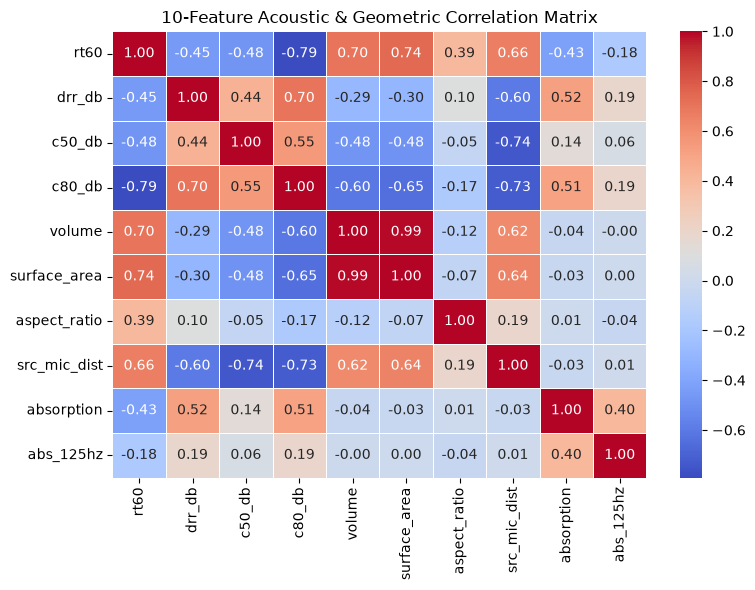

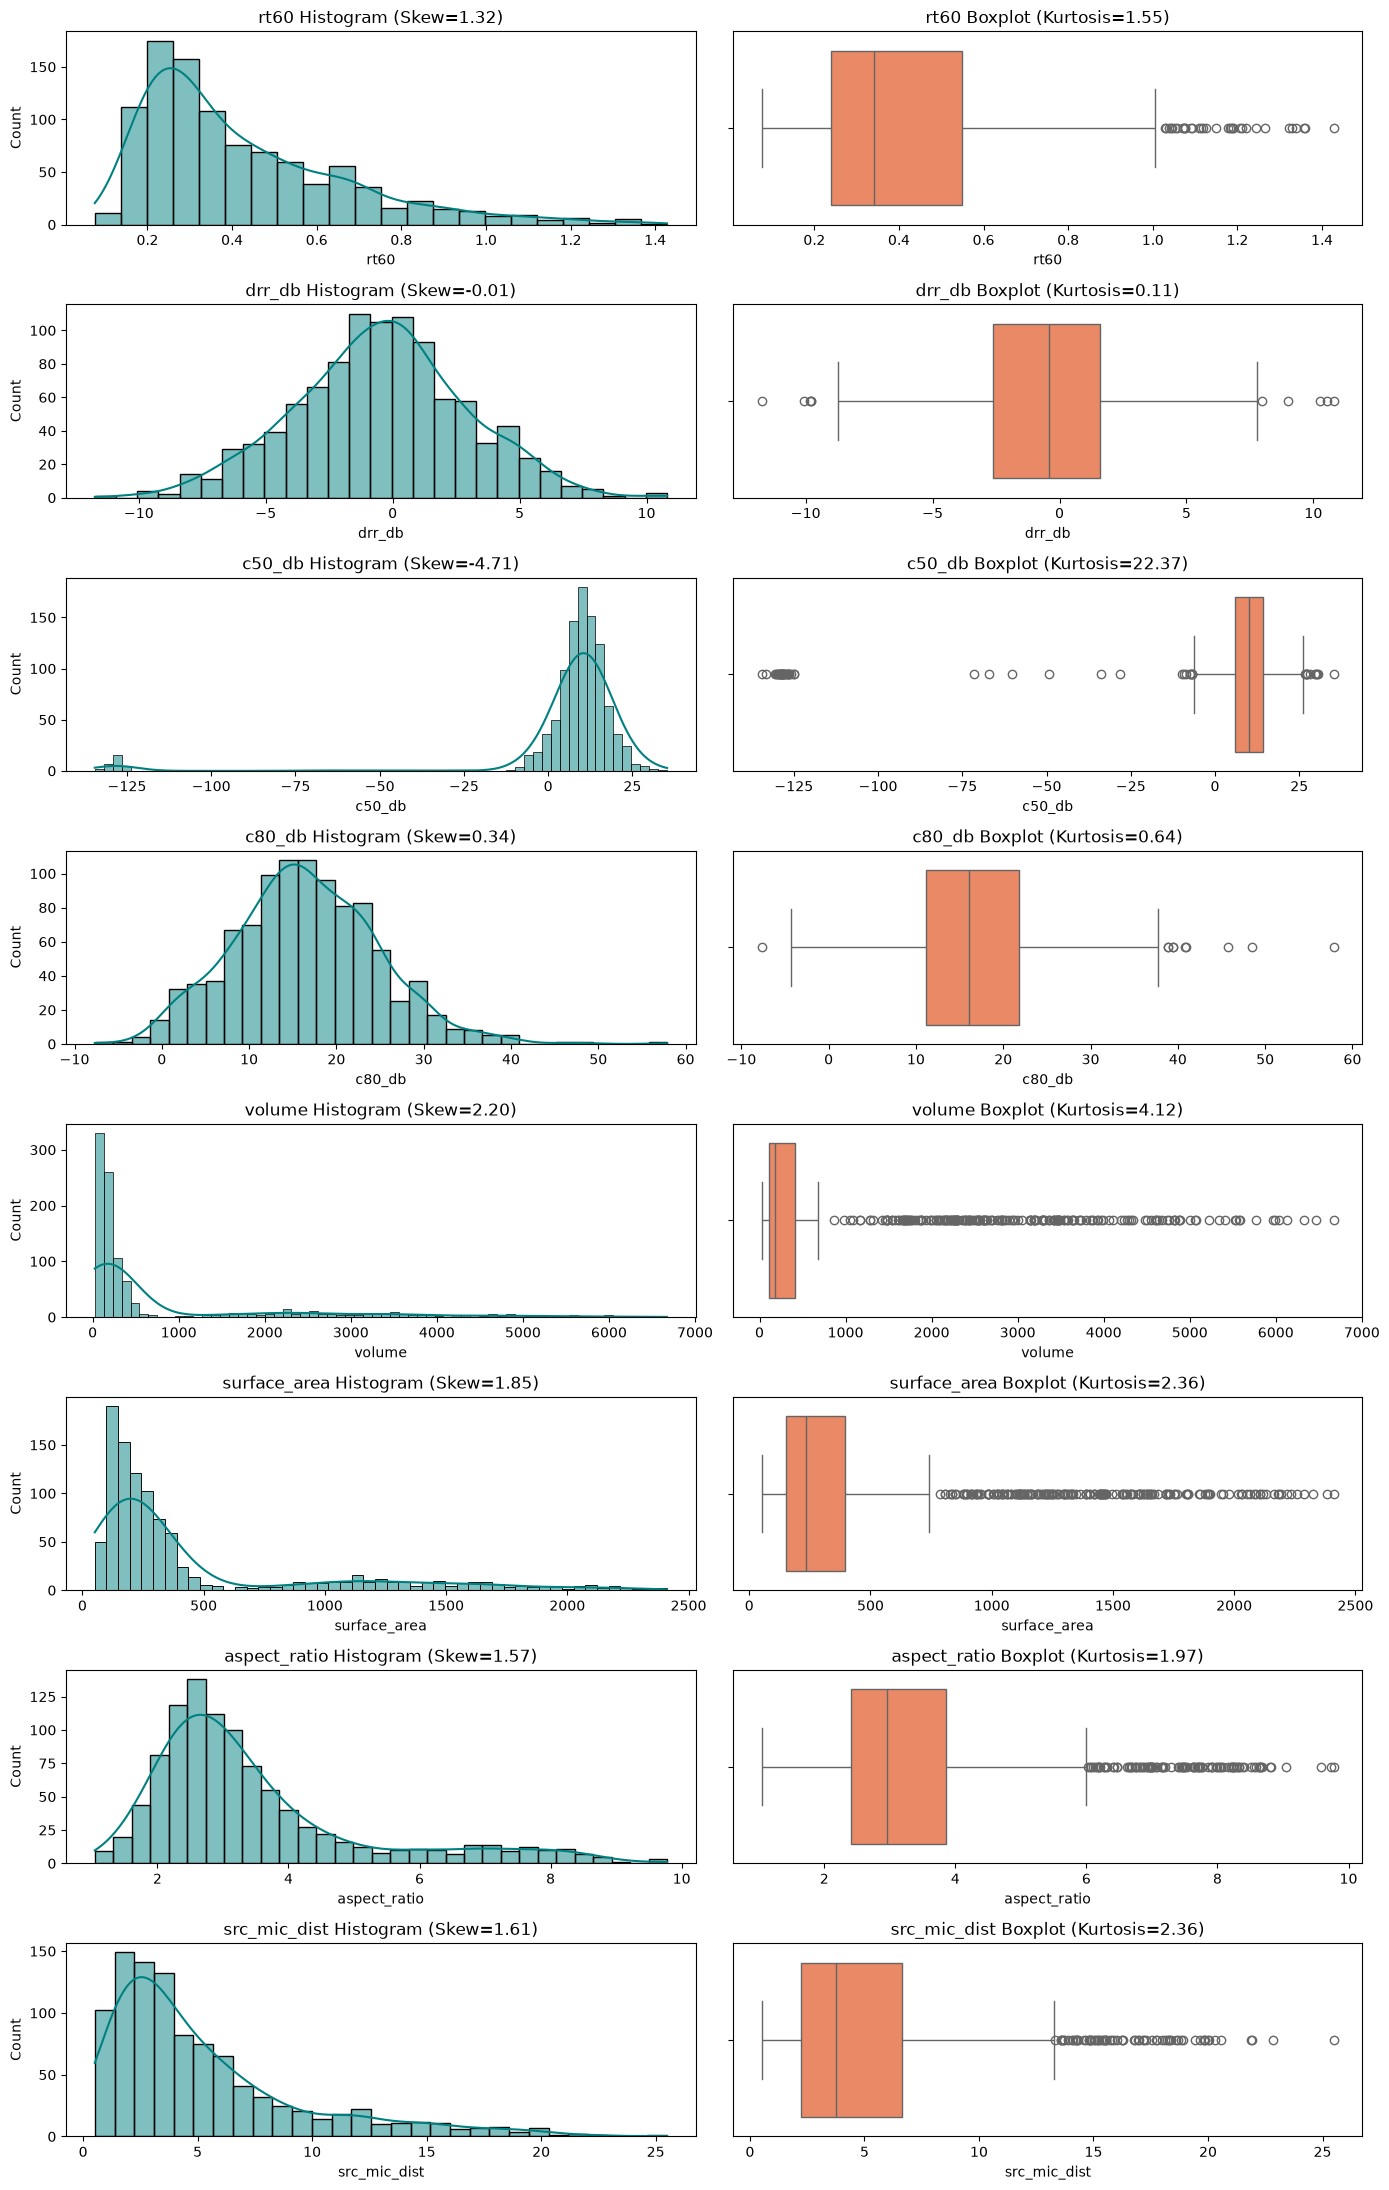

In [31]:
import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# 1. Safely unpack nested dictionaries and coordinate lists
def safe_eval(val):
    try:
        return ast.literal_eval(val) if isinstance(val, str) else val
    except Exception:
        return np.nan

metrics_parsed = df['metrics'].apply(safe_eval)
room_parsed = df['room_size'].apply(safe_eval)
source_parsed = df['source'].apply(safe_eval)
mic_parsed = df['microphone'].apply(safe_eval)
abs_bands_parsed = df['absorption_bands'].apply(safe_eval)

# Acoustic decay & clarity descriptors
df['rt60'] = metrics_parsed.apply(lambda x: x.get('rt60') if isinstance(x, dict) else np.nan)
df['drr_db'] = metrics_parsed.apply(lambda x: x.get('drr_db') if isinstance(x, dict) else np.nan)
df['c50_db'] = metrics_parsed.apply(lambda x: x.get('c50_db') if isinstance(x, dict) else np.nan)
df['c80_db'] = metrics_parsed.apply(lambda x: x.get('c80_db') if isinstance(x, dict) else np.nan)

# 3D Room Geometry descriptors
df['volume'] = room_parsed.apply(
    lambda x: x[0] * x[1] * x[2] if isinstance(x, list) and len(x) == 3 else np.nan
)
df['surface_area'] = room_parsed.apply(
    lambda x: 2.0 * (x[0]*x[1] + x[0]*x[2] + x[1]*x[2]) if isinstance(x, list) and len(x) == 3 else np.nan
)
df['aspect_ratio'] = room_parsed.apply(
    lambda x: max(x) / min(x) if isinstance(x, list) and len(x) == 3 and min(x) > 0 else np.nan
)

# Spatial Source-to-Microphone Euclidean Distance
df['src_mic_dist'] = [
    float(np.linalg.norm(np.array(s) - np.array(m)))
    if isinstance(s, list) and isinstance(m, list) and len(s) == 3 and len(m) == 3 else np.nan
    for s, m in zip(source_parsed, mic_parsed)
]

# Low-frequency absorption band (125 Hz)
df['abs_125hz'] = abs_bands_parsed.apply(
    lambda x: float(x.get('125')) if isinstance(x, dict) and '125' in x else np.nan
)

# Isolate the 10-feature numerical matrix
numeric_features = [
    'rt60', 'drr_db', 'c50_db', 'c80_db',
    'volume', 'surface_area', 'aspect_ratio',
    'src_mic_dist', 'absorption', 'abs_125hz'
]
df_num = df[numeric_features].dropna().copy()

# 2. Structural & Complete Statistical Summary (Including Data Types & Quantiles)
print("--- Structural Analysis ---")
print(f"Expanded Dataset Shape: {df.shape} | Cleaned Numeric Matrix Shape: {df_num.shape}")
print(f"Total Missing Values in Numeric Matrix: {df_num.isnull().sum().sum()}\n")

stats_df = pd.DataFrame({
    'Dtype': df_num.dtypes.astype(str),
    'Mean': df_num.mean(),
    'Std': df_num.std(),
    'Min': df_num.min(),
    'Median': df_num.median(),
    'Max': df_num.max(),
    'Skewness': df_num.apply(stats.skew),
    'Kurtosis': df_num.apply(stats.kurtosis)
}).round(3)
print("--- Statistical & Distribution Summary (10 Physical Features) ---")
display(stats_df)

# 3. Visualizations: Correlation Matrix + Histograms & Boxplots for Major Features
plt.figure(figsize=(8, 6))
sns.heatmap(df_num.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("10-Feature Acoustic & Geometric Correlation Matrix")
plt.tight_layout()
plt.show()

major_features = ['rt60', 'drr_db', 'c50_db', 'c80_db', 'volume', 'surface_area', 'aspect_ratio', 'src_mic_dist']
fig, axes = plt.subplots(len(major_features), 2, figsize=(14, 22))
for i, col in enumerate(major_features):
    sns.histplot(df_num[col], kde=True, ax=axes[i, 0], color='teal')
    axes[i, 0].set_title(f"{col} Histogram (Skew={stats_df.loc[col, 'Skewness']:.2f})")
    sns.boxplot(x=df_num[col], ax=axes[i, 1], color='coral')
    axes[i, 1].set_title(f"{col} Boxplot (Kurtosis={stats_df.loc[col, 'Kurtosis']:.2f})")
plt.tight_layout()
plt.show()

## 2. Exploratory Data Analysis: Interpretation

**Structural Analysis & Physical Correlations**
The extracted numerical matrix contains **1,000 observations across 10 continuous (`float64`) physical features** with **0 missing values**. The $10 \times 10$ correlation matrix confirms that our engineered features obey fundamental acoustic physics:
* **Sabine's Geometric Scaling:** `volume` and `surface_area` are nearly perfectly collinear ($r = 0.99$), and both strongly drive Reverberation Time `rt60` ($r = 0.70$ and $r = 0.74$) as well as source-to-microphone distance `src_mic_dist` ($r = 0.62$ and $r = 0.64$, with `src_mic_dist` vs. `rt60` at $r = 0.66$).
* **Reverberation vs. Clarity Trade-off:** `rt60` is strongly negatively correlated with Music Clarity `c80_db` ($r = -0.79$), Speech Clarity `c50_db` ($r = -0.48$), and Direct-to-Reverberant Ratio `drr_db` ($r = -0.45$). Conversely, `drr_db` positively drives `c80_db` ($r = 0.70$) and `c50_db` ($r = 0.44$), while `src_mic_dist` strongly reduces both `c50_db` ($r = -0.74$) and `c80_db` ($r = -0.73$).
* **Orthogonal Elongation & Material Absorption:** `aspect_ratio` is nearly uncorrelated with `surface_area` ($r = -0.07$) and `volume` ($r = -0.12$), proving that room elongation (e.g., narrow corridors vs. shoebox rooms) captures an independent geometric dimension that moderately lengthens `rt60` ($r = 0.39$). Mean `absorption` and low-frequency `abs_125hz` correlate positively ($r = 0.40$), and broadband `absorption` dampens `rt60` ($r = -0.43$) while boosting clarity (`drr_db`: $r = 0.52$, `c80_db`: $r = 0.51$).

**Distribution Analysis (Skewness & Kurtosis)**
* **Gaussian / Symmetric Features:** `drr_db` ($\text{Mean} = -0.458, \text{Skew} = -0.007, \text{Kurtosis} = 0.108$) and `absorption` ($\text{Mean} = 0.326, \text{Skew} = -0.048, \text{Kurtosis} = -0.166$) closely follow normal distributions, while `abs_125hz` ($\text{Mean} = 0.333, \text{Skew} = -0.044, \text{Kurtosis} = -1.167$) exhibits a symmetric uniform-like platykurtic spread.
* **Right-Skewed Geometric & Decay Features:** `volume` ($\text{Skew} = 2.199, \text{Kurtosis} = 4.121$), `surface_area` ($\text{Skew} = 1.848, \text{Kurtosis} = 2.364$), `src_mic_dist` ($\text{Skew} = 1.606, \text{Kurtosis} = 2.358$), `aspect_ratio` ($\text{Skew} = 1.573, \text{Kurtosis} = 1.968$), and `rt60` ($\text{Skew} = 1.322, \text{Kurtosis} = 1.554$) are all positively skewed. Most enclosures are small-to-medium residential or office spaces ($\text{median } V = 184.18\text{ m}^3$, $\text{median } RT_{60} = 0.340\text{ s}$), trailed by a long right tail of massive warehouses ($\max V = 6,674.76\text{ m}^3$, $\max RT_{60} = 1.428\text{ s}$).
* **Leptokurtic Speech Clarity (`c50_db`):** Exhibits severe negative skewness ($-4.713$) and extreme kurtosis ($22.367$), with a median of $10.211\text{ dB}$ but a minimum plunging to $-134.544\text{ dB}$.

**Outlier Exploration: Heavy Tails, Artifacts, Noise & Data Integrity**
* **Heavy Tails & Legitimate Extreme Values:** The boxplots for `volume`, `surface_area`, `src_mic_dist`, `aspect_ratio`, and `rt60` show numerous upper-tail outliers. In our domain, these are **legitimate physical extremes** (e.g., industrial warehouses up to $6,674.8\text{ m}^3$ or elongated corridors with `aspect_ratio` up to $9.78$), not corrupted records.
* **Measurement & Simulation Artifacts:** The extreme negative tail in `c50_db` ($\text{Kurtosis} = 22.367$, reaching $-134.544\text{ dB}$) reflects **mathematical boundary artifacts**. When the source-to-microphone distance is large ($\text{src\_mic\_dist} > 16\text{ m}$) in an elongated or reflective enclosure, almost zero acoustic energy arrives within the strict $50\text{ ms}$ early speech window, causing the logarithmic ratio $10\log_{10}(E_{\text{early}}/E_{\text{late}})$ to diverge sharply.
* **Possible Noise vs. Data-Entry Problems:** Because the corpus is programmatically generated and validated, there are **no typographical data-entry problems** (zero missing values, no impossible negative dimensions). Instead, "noise" manifests as stochastic variance from randomized 3D transducer coordinates (`rng_seed`) and frequency-band absorption fluctuations (`abs_125hz`).

## 3. Dimensionality Reduction (PCA)

**Objective & Standardization**
To uncover latent physical dimensions and eliminate multicollinearity across our 10 acoustic and geometric features, we apply Principal Component Analysis (PCA). Because PCA maximizes variance along orthogonal axes and is sensitive to scale differences (e.g., `volume` in $\text{m}^3$ vs. `absorption` in $[0,1]$), all 10 features are standardized using `StandardScaler` ($\mu = 0, \sigma = 1$).

**Analysis Goals**
* Compute the **explained variance ratio** and **cumulative explained variance** to select the optimal number of principal components.
* Visualize information retention via a **Scree Plot**.
* Inspect **component loadings** (`PC1`, `PC2`, `PC3`) and project the rooms into **2D and 3D subspaces** to evaluate global vs. local manifold structure.

--- PCA Variance Summary ---
PC01: Explained Variance = 0.4799 (47.99%) | Cumulative = 0.4799 (47.99%)
PC02: Explained Variance = 0.1690 (16.90%) | Cumulative = 0.6488 (64.88%)
PC03: Explained Variance = 0.1206 (12.06%) | Cumulative = 0.7695 (76.95%)
PC04: Explained Variance = 0.0919 (9.19%) | Cumulative = 0.8614 (86.14%)
PC05: Explained Variance = 0.0696 (6.96%) | Cumulative = 0.9310 (93.10%)
PC06: Explained Variance = 0.0403 (4.03%) | Cumulative = 0.9712 (97.12%)
PC07: Explained Variance = 0.0143 (1.43%) | Cumulative = 0.9855 (98.55%)
PC08: Explained Variance = 0.0096 (0.96%) | Cumulative = 0.9951 (99.51%)
PC09: Explained Variance = 0.0045 (0.45%) | Cumulative = 0.9996 (99.96%)
PC10: Explained Variance = 0.0004 (0.04%) | Cumulative = 1.0000 (100.00%)

--- Top 3 Principal Component Loadings ---


,PC1,PC2,PC3
rt60,-0.403,-0.049,0.261
drr_db,0.307,0.311,0.231
c50_db,0.325,-0.093,-0.006
c80_db,0.415,0.161,-0.030
volume,-0.366,0.325,-0.187
surface_area,-0.377,0.320,-0.135
aspect_ratio,-0.059,-0.082,0.890
src_mic_dist,-0.389,0.158,0.116
absorption,0.173,0.615,0.128
abs_125hz,0.077,0.499,0.051


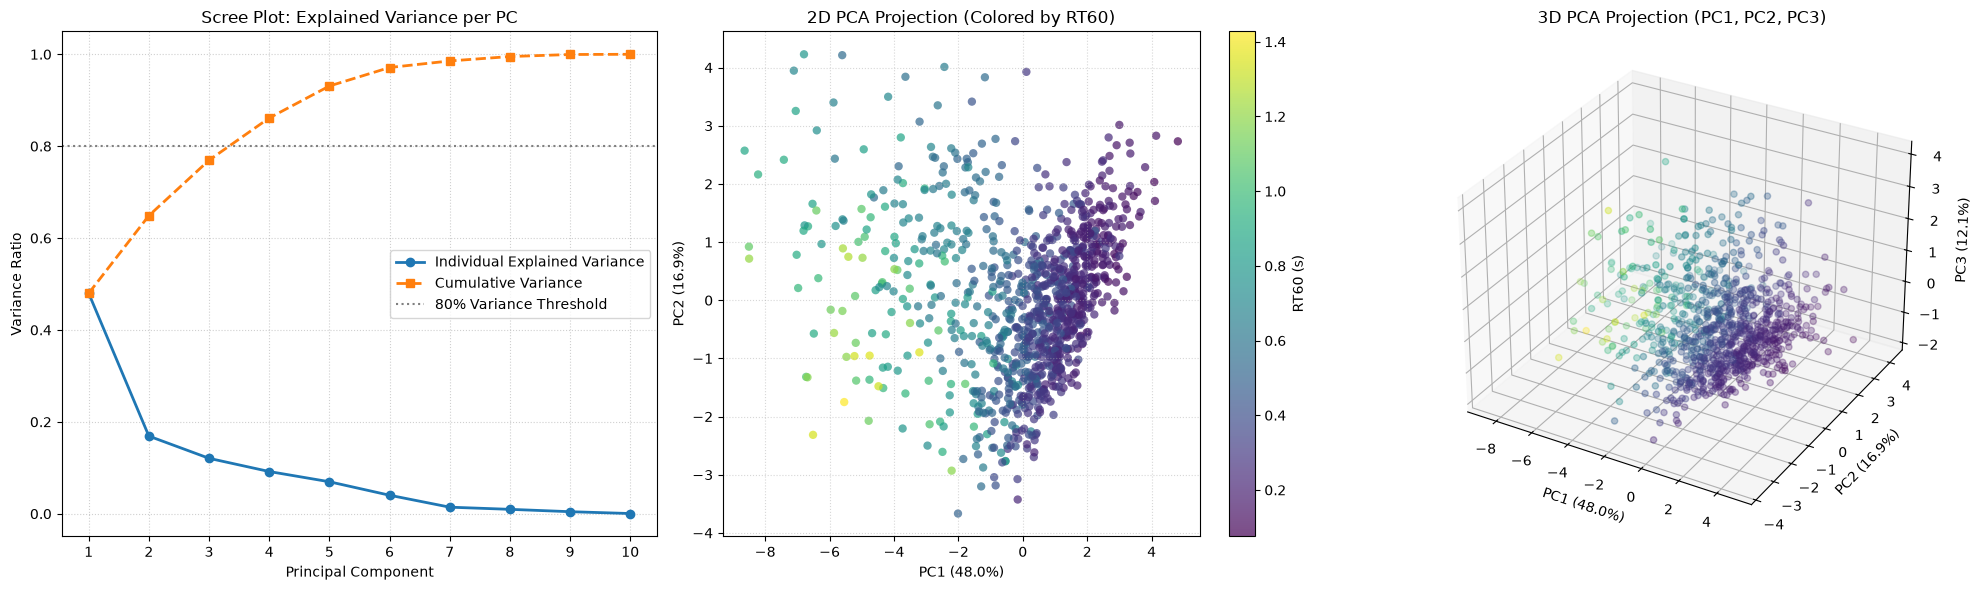

In [32]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Standardize the 10-feature space
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_num)

# 2. Fit PCA across all 10 dimensions
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("--- PCA Variance Summary ---")
for i, (ev, cv) in enumerate(zip(explained_variance, cumulative_variance)):
    print(f"PC{i+1:02d}: Explained Variance = {ev:.4f} ({ev*100:.2f}%) | Cumulative = {cv:.4f} ({cv*100:.2f}%)")

# 3. Principal Component Loadings (PC1, PC2, PC3)
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(len(df_num.columns))],
    index=df_num.columns
)
print("\n--- Top 3 Principal Component Loadings ---")
display(loadings[['PC1', 'PC2', 'PC3']].round(3))

# 4. Visualizations: Scree Plot, 2D Projection, and Native 3D Projection (100% OS & GitHub Compatible)
fig = plt.figure(figsize=(20, 6))

# Panel 1: Scree Plot
ax1 = fig.add_subplot(1, 3, 1)
pcs = range(1, len(explained_variance) + 1)
ax1.plot(pcs, explained_variance, marker='o', linewidth=2, label='Individual Explained Variance')
ax1.plot(pcs, cumulative_variance, marker='s', linestyle='--', linewidth=2, label='Cumulative Variance')
ax1.axhline(0.80, color='gray', linestyle=':', label='80% Variance Threshold')
ax1.set_title('Scree Plot: Explained Variance per PC')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Variance Ratio')
ax1.set_xticks(list(pcs))
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

# Panel 2: 2D PCA Projection
ax2 = fig.add_subplot(1, 3, 2)
sc2d = ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=df_num['rt60'], cmap='viridis', alpha=0.7, edgecolors='none')
ax2.set_title('2D PCA Projection (Colored by RT60)')
ax2.set_xlabel(f'PC1 ({explained_variance[0]*100:.1f}%)')
ax2.set_ylabel(f'PC2 ({explained_variance[1]*100:.1f}%)')
fig.colorbar(sc2d, ax=ax2, label='RT60 (s)')
ax2.grid(True, linestyle=':', alpha=0.5)

# Panel 3: Native 3D PCA Projection
ax3 = fig.add_subplot(1, 3, 3, projection='3d')
sc3d = ax3.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=df_num['rt60'], cmap='viridis', alpha=0.65, s=20)
ax3.set_title('3D PCA Projection (PC1, PC2, PC3)')
ax3.set_xlabel(f'PC1 ({explained_variance[0]*100:.1f}%)')
ax3.set_ylabel(f'PC2 ({explained_variance[1]*100:.1f}%)')
ax3.set_zlabel(f'PC3 ({explained_variance[2]*100:.1f}%)')

plt.tight_layout()
plt.show()

## 3. Dimensionality Reduction: PCA Interpretation

**1. Optimal Number of Components & Information Loss**
From the Scree Plot and variance summary, the first **3 Principal Components capture 76.95%** of total variance, **4 PCs capture 86.14%**, and **5 PCs capture 93.10%**.
* **Adequate Representation:** Retaining **3 to 4 components** is optimal. A **3D projection (76.95% variance)** loses **23.05%** of the information but is ideal for visual manifold inspection, whereas retaining **4 components (86.14% variance)** loses only **13.86%** of the variance while cutting dimensionality by 60%. Notice that `PC08`, `PC09`, and `PC10` together account for only $1.45\%$ of variance (`PC10` is $0.04\%$), confirming near-zero information loss when discarding the trailing axes.

**2. Feature Collinearity & Principal Component Interpretation**
Strong physical collinearity (`volume` vs. `surface_area` $r=0.99$; `rt60` vs. `c80_db` $r=-0.79$) causes PCA to merge redundant variables into orthogonal physical axes:
* **PC1 (47.99% Variance — Global Acoustic Scale: Reverberation vs. Clarity):** Balances clarity metrics (`c80_db`: $0.415$, `c50_db`: $0.325$, `drr_db`: $0.307$) against room scale and decay (`rt60`: $-0.403$, `src_mic_dist`: $-0.389$, `surface_area`: $-0.377$, `volume`: $-0.366$). Moving left along PC1 transitions from small, dry, high-clarity rooms to huge, reverberant spaces.
* **PC2 (16.90% Variance — Boundary Absorption & Direct Energy):** Dominated by material absorption (`absorption`: $0.615$, `abs_125hz`: $0.499$) alongside enclosure size (`volume`: $0.325$, `surface_area`: $0.320$, `drr_db`: $0.311$). It separates highly damped/absorptive large enclosures from reflective small enclosures.
* **PC3 (12.06% Variance — Geometric Elongation / Aspect Ratio):** Heavily loaded on `aspect_ratio` ($0.890$) and `rt60` ($0.261$). This component isolates elongated geometries (such as narrow corridors) from standard shoebox rooms.

**3. Structural & Methodological Discussion**
* **Effectiveness & Redundancy:** The reduced representation is much more effective for downstream distance-based learning than the raw 10D space. Because `volume`, `surface_area`, `src_mic_dist`, and `rt60` are governed by Sabine's equation, the raw dataset contains severe multicollinearity (`PC10` explains just $0.04\%$ variance). PCA eliminates this redundancy so Euclidean distances are not double-counted across collinear geometric features.
* **Local vs. Global Structure & Cluster Separation:** The 2D and 3D projections reveal a **continuous global manifold** with a smooth `rt60` gradient along PC1, rather than disjoint spherical islands. However, there is a distinct low-density tail extending toward negative PC1 (large warehouses and extreme $C_{50}$ drop-offs).
* **Stability:** Because the top eigenvalues are well-separated ($47.99\% \gg 16.90\% \gg 12.06\%$), the principal axes are mathematically stable. However, because PCA minimizes squared reconstruction error, the orientation of higher components can still be pulled by extreme leptokurtic outliers (such as `c50_db`).
* **Computational Cost:** Computing the SVD on a $1000 \times 10$ matrix is instantaneous ($O(N D^2 + D^3)$), and reducing $D$ from $10$ to $3\text{–}4$ lowers the computational cost and mitigates distance concentration for downstream $O(N^2)$ neighborhood algorithms.
* **Interpretability:** While linear combinations are more abstract than raw units like $\text{m}^3$ or seconds, our loading matrix maps cleanly to three intuitive physical concepts: *(1) Acoustic Scale/Clarity*, *(2) Material Absorption*, and *(3) Corridor Elongation*.

## 4 Clustering Analysis

**Objective**
We apply unsupervised clustering to discover hidden structures within the acoustic feature space. We evaluate three distinct algorithms to compare how density-based and centroid-based approaches interpret the data.

**Algorithm 1: K-Means**
*   **Mathematical Intuition:** Minimizes the within-cluster sum of squares (WCSS) by iteratively updating centroids and assigning points via Euclidean distance.
*   **Assumptions:** Assumes clusters are spherical, isotropic, and have roughly equal variance.
*   **Strengths/Weaknesses:** Computationally highly efficient (Strength), but fails on non-convex shapes and is heavily sensitive to initial centroid placement and outliers (Weakness).

**Algorithm 2: DBSCAN**
*   **Mathematical Intuition:** Groups points that are closely packed together based on a distance radius ($\epsilon$) and a minimum number of points, marking low-density regions as noise.
*   **Assumptions:** Assumes continuous dense regions separate distinct clusters.
*   **Strengths/Weaknesses:** Discovers arbitrarily shaped clusters and inherently isolates noise (Strength), but struggles if clusters have varying densities (Weakness).

**Algorithm 3: Hierarchical Clustering (Agglomerative)**
*   **Mathematical Intuition:** A bottom-up approach where each observation starts in its own cluster, and pairs are iteratively merged based on linkage criteria (Ward's variance minimization) until a hierarchy tree forms.
*   **Assumptions:** Assumes data contains nested structures or hierarchies.
*   **Strengths/Weaknesses:** Provides an interpretable dendrogram without pre-specifying the number of clusters (Strength), but scales poorly computationally for large datasets (Weakness).

--- Clustering Evaluation: Intra-Cluster vs. Global Variance ---
Global Standardized Variance:        10.0000
K-Means Intra-Cluster Variance:      5.4712 (Silhouette: 0.224)
Hierarchical Intra-Cluster Variance: 5.8995 (Silhouette: 0.376)
DBSCAN Intra-Cluster Variance:       6.5877 (Excluding Noise)

--- Cluster Distribution Breakdown ---
K-Means Counts:      {0: 432, 2: 394, 1: 174}
Hierarchical Counts: {0: 791, 1: 175, 2: 34}
DBSCAN Counts (-1 = Noise): {0: 902, -1: 98}


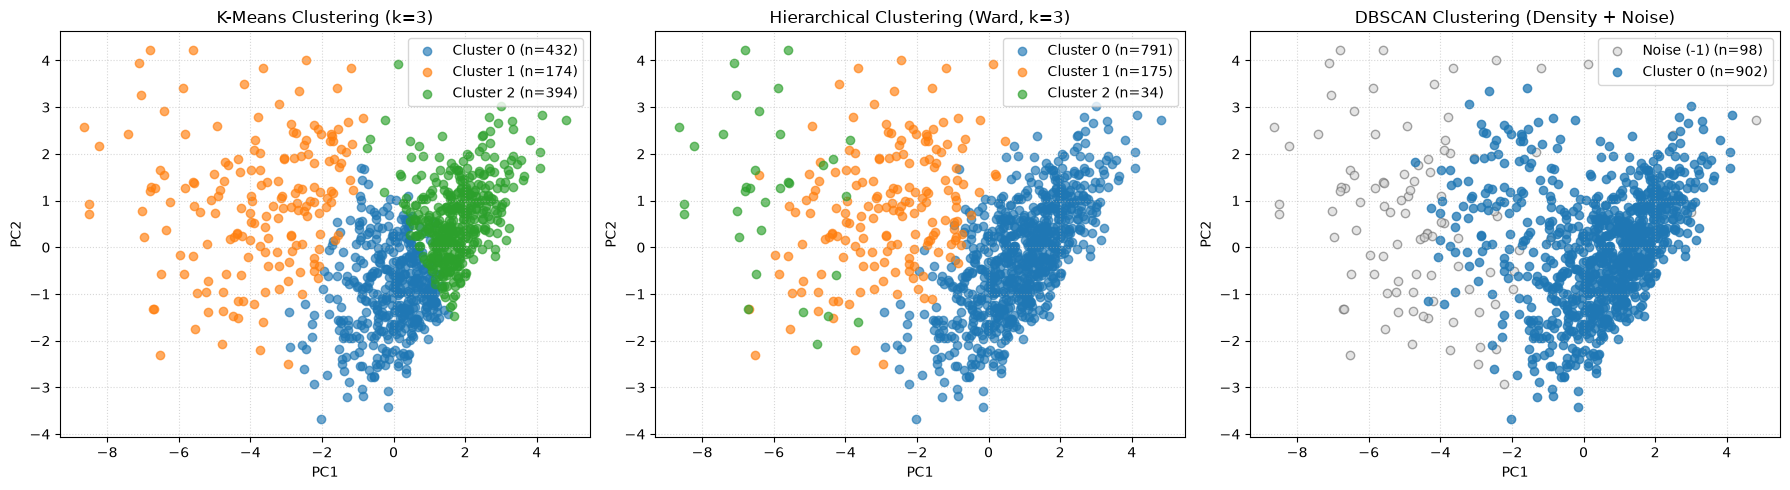

In [33]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score

# 1. Global Variance & Custom Weighted Intra-Cluster Variance Metric
global_var = np.var(X_scaled, axis=0).sum()

def evaluate_cluster_variance(X, labels):
    """Calculates weighted average intra-cluster variance (excluding DBSCAN noise = -1)."""
    unique_labels = [lbl for lbl in set(labels) if lbl != -1]
    if not unique_labels:
        return np.nan
    total_intra_var = 0.0
    n_clustered = 0
    for label in unique_labels:
        cluster_points = X[labels == label]
        total_intra_var += np.var(cluster_points, axis=0).sum() * len(cluster_points)
        n_clustered += len(cluster_points)
    return total_intra_var / n_clustered if n_clustered > 0 else np.nan

# 2. Fit the 3 Clustering Algorithms
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

hierarchical = AgglomerativeClustering(n_clusters=3, linkage='ward')
hierarchical_labels = hierarchical.fit_predict(X_scaled)

dbscan = DBSCAN(eps=1.6, min_samples=10)
dbscan_labels = dbscan.fit_predict(X_scaled)

# 3. Print Quantitative Evaluation & Cluster Size Breakdown
print("--- Clustering Evaluation: Intra-Cluster vs. Global Variance ---")
print(f"Global Standardized Variance:        {global_var:.4f}")
print(f"K-Means Intra-Cluster Variance:      {evaluate_cluster_variance(X_scaled, kmeans_labels):.4f} (Silhouette: {silhouette_score(X_scaled, kmeans_labels):.3f})")
print(f"Hierarchical Intra-Cluster Variance: {evaluate_cluster_variance(X_scaled, hierarchical_labels):.4f} (Silhouette: {silhouette_score(X_scaled, hierarchical_labels):.3f})")
print(f"DBSCAN Intra-Cluster Variance:       {evaluate_cluster_variance(X_scaled, dbscan_labels):.4f} (Excluding Noise)\n")

print("--- Cluster Distribution Breakdown ---")
print("K-Means Counts:     ", pd.Series(kmeans_labels).value_counts().to_dict())
print("Hierarchical Counts:", pd.Series(hierarchical_labels).value_counts().to_dict())
print("DBSCAN Counts (-1 = Noise):", pd.Series(dbscan_labels).value_counts().to_dict())

# 4. Visualize on 2D PCA Projection with Explicit Legends
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pca_x, pca_y = X_pca[:, 0], X_pca[:, 1]

# K-Means
for lbl in sorted(set(kmeans_labels)):
    mask = kmeans_labels == lbl
    axes[0].scatter(pca_x[mask], pca_y[mask], alpha=0.65, label=f'Cluster {lbl} (n={mask.sum()})')
axes[0].set_title('K-Means Clustering (k=3)')
axes[0].legend()

# Hierarchical
for lbl in sorted(set(hierarchical_labels)):
    mask = hierarchical_labels == lbl
    axes[1].scatter(pca_x[mask], pca_y[mask], alpha=0.65, label=f'Cluster {lbl} (n={mask.sum()})')
axes[1].set_title('Hierarchical Clustering (Ward, k=3)')
axes[1].legend()

# DBSCAN (Explicitly color Noise = -1 in gray)
for lbl in sorted(set(dbscan_labels)):
    mask = dbscan_labels == lbl
    if lbl == -1:
        axes[2].scatter(pca_x[mask], pca_y[mask], c='lightgray', edgecolors='dimgray', alpha=0.6, label=f'Noise (-1) (n={mask.sum()})')
    else:
        axes[2].scatter(pca_x[mask], pca_y[mask], alpha=0.75, label=f'Cluster {lbl} (n={mask.sum()})')
axes[2].set_title('DBSCAN Clustering (Density + Noise)')
axes[2].legend()

for ax in axes:
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

## 4.1 Clustering Analysis: Sample-Space Interpretation

**1. Evaluation: Intra-Cluster vs. Global Variance & Metric Suitability**
The global standardized variance across our 10 features is **10.0000**.
* **K-Means ($k=3$):** Achieved the lowest weighted intra-cluster variance (**5.4712**, a 45.3% reduction), partitioning the rooms into three balanced groups (`Cluster 0`: $n=432$, `Cluster 2`: $n=394$, `Cluster 1`: $n=174$), with a **Silhouette Score of 0.224**.
* **Hierarchical Clustering (Ward, $k=3$):** Achieved an intra-cluster variance of **5.8995** (`Cluster 0`: $n=791$, `Cluster 1`: $n=175$, `Cluster 2`: $n=34$), but reached a substantially higher **Silhouette Score of 0.376** by isolating the 34 most extreme acoustic outliers into `Cluster 2`.
* **DBSCAN ($\varepsilon=1.6, \text{min\_samples}=10$):** Yielded the highest intra-cluster variance (**6.5877**, excluding noise) because it merged **902 rooms** into a single continuous macro-cluster (`Cluster 0`) while isolating **98 peripheral rooms** as `Noise (-1)`.
* **Is Intra-Cluster Variance Suitable? Alternative Metrics:** Intra-cluster variance is mathematically biased toward centroid-based algorithms (K-Means and Ward linkage explicitly minimize within-cluster sum of squares) and monotonically decreases as $k$ increases. It is **unsuitable for DBSCAN**, where a single non-convex or continuous density manifold naturally spans a wide variance. A superior alternative is the **Silhouette Coefficient** (which balances intra-cluster cohesion $a(i)$ against nearest-cluster separation $b(i)$) or **DBCV (Density-Based Clustering Validation)** for arbitrary shapes.

**2. Real-World Interpretation of the Clusters**
Mapping the clusters onto the PCA axes reveals their physical meaning:
* **Right-Hand Cluster (High PC1 — K-Means Cluster 2):** Small, dry, high-clarity enclosures (small offices and living rooms) with short $RT_{60}$ and high $C_{50}/C_{80}$.
* **Central Transition Zone (Mid PC1 — K-Means Cluster 0):** Medium-sized rooms with moderate reverberation and balanced direct-to-reverberant energy.
* **Left-Hand Tail (Negative PC1 — K-Means Cluster 1 / Hierarchical Cluster 2 / DBSCAN Noise):** Large reverberant warehouses and highly elongated corridors with long $RT_{60}$, large source-to-microphone distances, and severe speech clarity drop-offs.

**3. Method Comparison: Why Algorithms Disagree**
* **Centroid-Based vs. Density-Based Geometry:** Because physical room dimensions scale continuously, the data forms a single connected density gradient rather than separated spherical blobs. K-Means forces linear Voronoi hyperplanes across this continuum to equalize cluster variance. Ward's Hierarchical clustering merges the dense core ($n=791$) and slices off the sparse tail ($n=175$ and $n=34$). DBSCAN follows density connectivity, bridging the entire main cloud into one cluster ($n=902$) and treating the sparse tail as noise ($n=98$).
* **Sensitivity to Hyperparameters:** K-Means and Hierarchical clustering require pre-specifying $k=3$, forcing artificial boundaries even when no natural gap exists. DBSCAN is highly sensitive to $\varepsilon$ and `min_samples`: due to variable density between the compact core of small rooms and the sparse tail of large warehouses, a single global $\varepsilon$ cannot split the core without labeling the entire warehouse tail as noise.
* **When Clustering Fails:** Clustering fails to find "natural categories" when applied to continuous physical laws (Sabine's continuum), high-dimensional spaces where Euclidean distances concentrate, or datasets with severe density gradients.

### 4.2 Clustering on the Feature Space ($X^T$)

**Objective & Methodology**
To uncover hidden feature hierarchies, redundancies, and orthogonal variables, we transpose the standardized data matrix ($X^T \in \mathbb{R}^{10 \times 1000}$) so that the 10 physical features become the observations. We apply Agglomerative Ward Clustering ($k=4$) and visualize the hierarchical correlation dendrogram via a Seaborn Clustermap.

--- Feature Space Clustering (X^T) ---


,Feature,Feature_Cluster
0,drr_db,0
1,c50_db,0
2,c80_db,0
3,absorption,0
4,rt60,1
5,volume,1
6,surface_area,1
7,src_mic_dist,1
8,aspect_ratio,2
9,abs_125hz,3


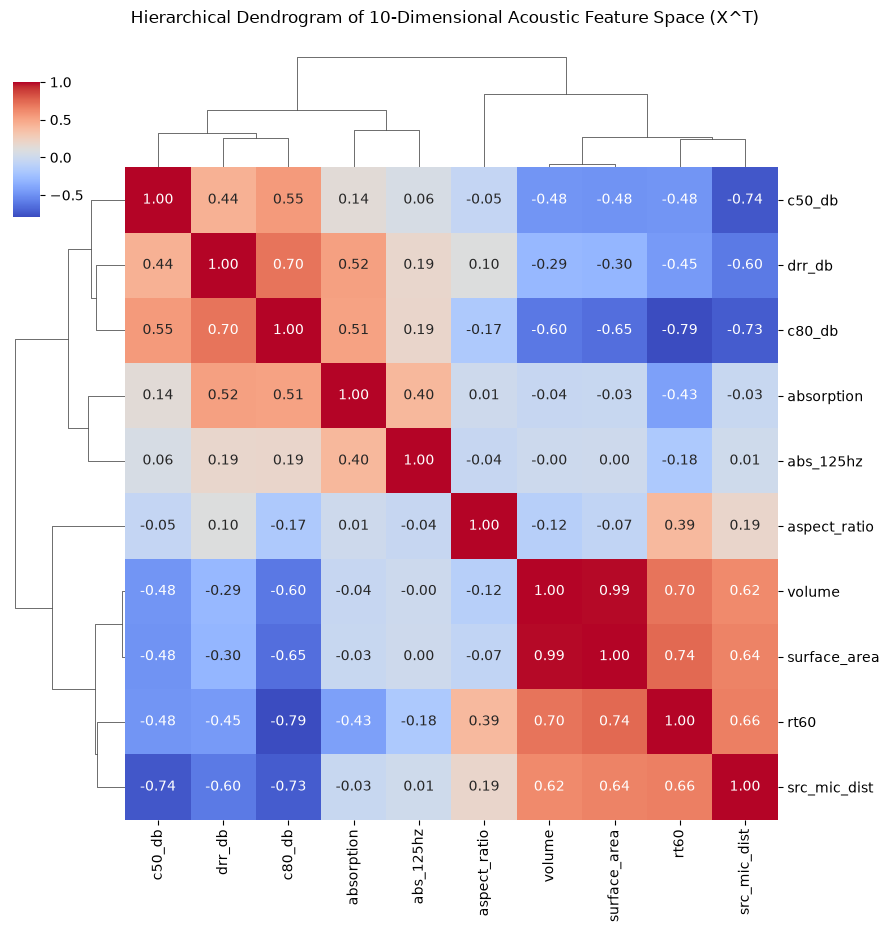

In [34]:
# 1. Transpose the standardized matrix: Features become rows (10, 1000)
X_T = X_scaled.T

# 2. Hierarchical Clustering on the Feature Space
feature_clustering = AgglomerativeClustering(n_clusters=4, linkage='ward')
feature_labels = feature_clustering.fit_predict(X_T)

feature_groups = pd.DataFrame({
    'Feature': df_num.columns,
    'Feature_Cluster': feature_labels
}).sort_values(by='Feature_Cluster').reset_index(drop=True)

print("--- Feature Space Clustering (X^T) ---")
display(feature_groups)

# 3. Clustermap Dendrogram of the 10 Physical Features
g = sns.clustermap(
    df_num.corr(), annot=True, cmap='coolwarm', fmt=".2f", figsize=(9, 9),
    dendrogram_ratio=(0.15, 0.15), cbar_pos=(0.02, 0.8, 0.03, 0.15)
)
g.fig.suptitle("Hierarchical Dendrogram of 10-Dimensional Acoustic Feature Space (X^T)", y=1.03)
plt.show()

## 4.2 Clustering on the Feature Space ($X^T$): Interpretation

**1. Information Obtained & Redundant Feature Groups**
Clustering the transposed matrix $X^T \in \mathbb{R}^{10 \times 1000}$ groups variables by similarity across all 1,000 rooms, uncovering four functional physical families:
* **Feature Cluster 0 (Clarity & Broadband Absorption):** `drr_db`, `c50_db`, `c80_db`, and `absorption`. These features measure early-to-late sound energy ratios and wall damping, which rise together in dry, acoustically treated rooms.
* **Feature Cluster 1 (Macro-Scale Geometry & Reverberation Decay):** `rt60`, `volume`, `surface_area`, and `src_mic_dist`. The dendrogram highlights near-perfect redundancy between `volume` and `surface_area` ($r = 0.99$), which together bound `src_mic_dist` ($r = 0.62\text{–}0.64$) and physically drive reverberation time `rt60` ($r = 0.70\text{–}0.74$) via Sabine's formula $RT_{60} \propto V / S\bar{\alpha}$.

**2. Isolated & Distinct Features**
* **Feature Cluster 2 (`aspect_ratio`):** Isolated in its own singleton branch. Its near-zero correlation with `volume` ($r = -0.12$) and `surface_area` ($r = -0.07$) proves that geometric elongation (corridors vs. cubic rooms) is structurally independent of overall room size.
* **Feature Cluster 3 (`abs_125hz`):** Isolated into its own cluster. While moderately linked to mean `absorption` ($r = 0.40$), low-frequency bass absorption behaves independently of geometry ($r = 0.00$ with `surface_area`), representing stochastic material variance in the 125 Hz octave band.

**3. Insights Beyond Sample Clustering & Domain Applications**
Sample clustering only shows how rooms partition, whereas feature-space clustering exposes **structural multicollinearity and hierarchy**, explaining *why* PCA compressed 86.14% of the variance into 4 components (the four feature clusters directly mirror our top principal components). In broader data science, clustering $X^T$ is vital for **bioinformatics** (finding co-expressed gene modules), **finance** (grouping collinear market assets for portfolio diversification), and **IoT/sensor networks** (pruning redundant physical sensors before training distance-based models).

## 5. Multi-Dimensional Anomaly Detection

**Objective**
Identify abnormal acoustic behaviors, simulation boundary artifacts, and extreme non-Sabine room geometries within the 10-dimensional feature space. We apply and compare three distinct paradigms:

**5.1 Z-Score Method (Parametric / Univariate Statistical)**
* **Mathematical Intuition:** Computes the standardized distance $Z_{ij} = \frac{|x_{ij} - \mu_j|}{\sigma_j}$ for each feature $j$ independently, flagging an observation as anomalous if $\max_j Z_{ij} > 3$.
* **Assumption of Gaussianity:** Strictly assumes each feature is normally distributed ($X_j \sim \mathcal{N}(\mu_j, \sigma_j^2)$), where $|Z| > 3$ corresponds to the extreme $0.27\%$ tail. In skewed or heavy-tailed features (`c50_db`, `volume`), the sample mean and standard deviation are inflated, causing Z-score to over-flag heavy tails while missing subtle outliers.
* **Feature-Wise vs. Global Anomaly Detection & High-Dimensional Failure:** Because Z-Score evaluates features one at a time (axis-parallel), it completely misses **multivariate interaction anomalies**—rooms whose individual features are all within $[-2\sigma, +2\sigma]$, but whose *combination* violates physical laws (e.g., a tiny room with a very long reverberation time $RT_{60}$).

**5.2 Isolation Forest (Tree-Based Random Partitioning)**
* **Isolation Mechanism & Random Partitioning:** Builds an ensemble of random binary trees ($i\text{Trees}$) by recursively selecting a random feature and a uniform random split value between its min and max. Because anomalies are "few and different" and lie in sparse regions, random cuts isolate them near the root (short path length $h(x)$), whereas normal points require many splits to isolate.
* **Anomaly Score Calculation & Interpretation:** The anomaly score for observation $x$ in a sample of size $n$ is defined as:
  $$s(x, n) = 2^{-\frac{E(h(x))}{c(n)}}$$
  where $E(h(x))$ is the average path length across all trees and $c(n)$ is the average path length of an unsuccessful search in a Binary Search Tree.
  * **High Score ($s \to 1$):** Very short average path length $E(h(x)) \to 0$, meaning the room is a clear **anomaly** isolated in only a few splits.
  * **Low Score ($s < 0.5$):** Long path length $E(h(x)) \ge c(n)$, meaning the room lies deep inside the dense normal interior. *(Note: `scikit-learn` shifts this score so negative values $< 0$ denote anomalies).*
* **Contamination Parameter:** Specifies the expected proportion of outliers (set to `contamination = 0.05`), which sets the quantile cutoff on the anomaly score distribution.
* **Advantages & Limitations in High Dimensions:** Escapes the Curse of Dimensionality because it does not compute pairwise Euclidean distances ($O(N \log N)$ complexity). However, axis-parallel splits can struggle with local density anomalies hidden inside non-linear manifolds.

**5.3 Local Outlier Factor — LOF (Density-Based Neighborhood)**
* **Local Density Estimation & Neighborhood Effects:** Computes the local reachability density $\text{lrd}_k(x)$ of a point based on the distance to its $k$-nearest neighbors, and compares it to the average $\text{lrd}_k$ of those neighbors:
  $$\text{LOF}_k(x) = \frac{\sum_{o \in N_k(x)} \frac{\text{lrd}_k(o)}{\text{lrd}_k(x)}}{|N_k(x)|}$$
  A score $\text{LOF}_k(x) \approx 1$ indicates normal density matching its neighbors, while $\text{LOF}_k(x) \gg 1$ flags a local outlier.
* **Sensitivity to Parameter $k$:** Small $k$ values focus on micro-neighborhoods (risking false positives from local noise), whereas very large $k$ values degenerate into global distance outlier detection. Setting $k = 20$ balances local neighborhood context against statistical stability.
* **Global vs. Local Anomalies:** Unlike Z-Score and Isolation Forest (which primarily target global extremes on the outer periphery), LOF detects **local anomalies**—rooms that sit well inside global bounds but are isolated relative to their immediate acoustic neighborhood.

--- Anomaly Detection Counts (10-Feature Space) ---
Z-Score Anomalies (|Z| > 3):        82
Isolation Forest Anomalies (5%):    50
Local Outlier Factor Anomalies (5%): 50


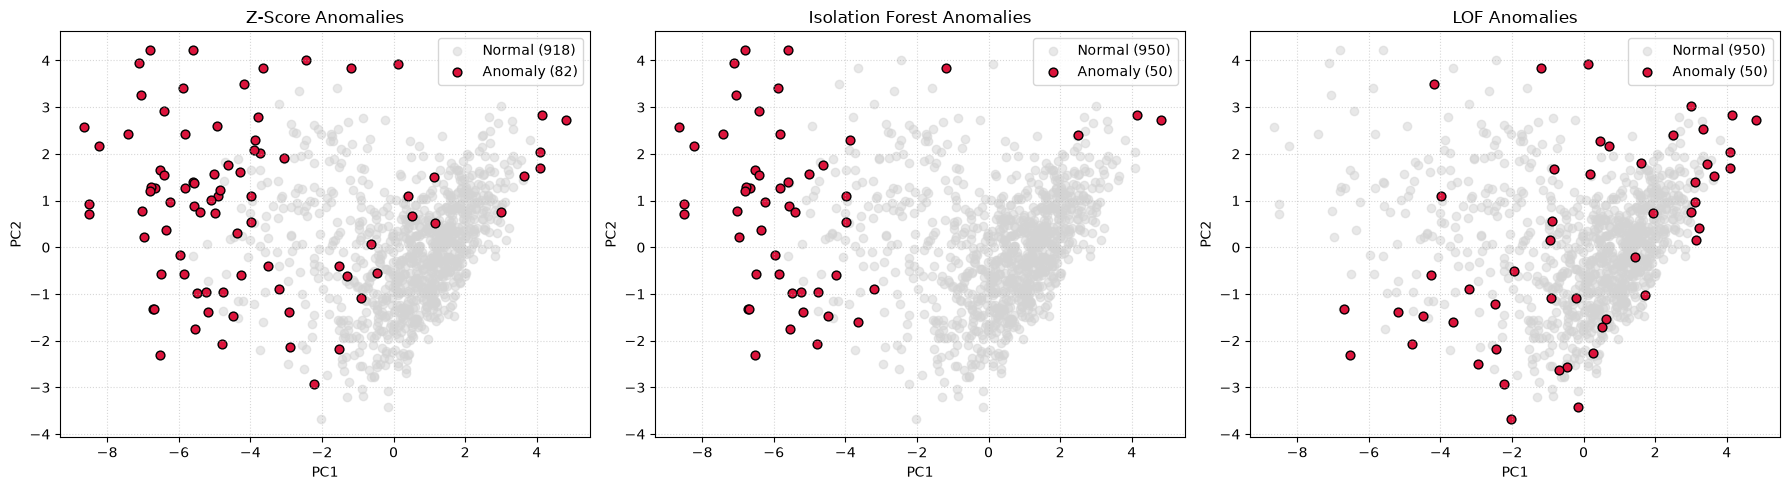

In [35]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from scipy.stats import zscore

# 1. Anomaly Detection Methods
z_scores = np.abs(zscore(df_num))
z_anomalies = (z_scores > 3).any(axis=1)  # Removed .to_numpy()

iso_forest = IsolationForest(contamination=0.05, random_state=42)
iso_anomalies = (iso_forest.fit_predict(X_scaled) == -1)

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
lof_anomalies = (lof.fit_predict(X_scaled) == -1)

print("--- Anomaly Detection Counts (10-Feature Space) ---")
print(f"Z-Score Anomalies (|Z| > 3):        {z_anomalies.sum()}")
print(f"Isolation Forest Anomalies (5%):    {iso_anomalies.sum()}")
print(f"Local Outlier Factor Anomalies (5%): {lof_anomalies.sum()}")

# 2. Visualize Anomalies on 2D PCA Space
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
methods = [('Z-Score', z_anomalies), ('Isolation Forest', iso_anomalies), ('LOF', lof_anomalies)]

for ax, (name, mask) in zip(axes, methods):
    ax.scatter(pca_x[~mask], pca_y[~mask], c='lightgray', alpha=0.5, label=f'Normal ({(~mask).sum()})')
    ax.scatter(pca_x[mask], pca_y[mask], c='crimson', edgecolor='black', s=40, label=f'Anomaly ({mask.sum()})')
    ax.set_title(f'{name} Anomalies')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend()
    ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

## 5.4 Multi-Dimensional Anomaly Detection: Visual Interpretation

* **Z-Score (`82` Anomalies Flagged, $\vert{}Z\vert{} > 3$):** Flags the largest number of observations (`8.2%` of the corpus). Because it applies a univariate $3\sigma$ cutoff across all 10 features independently, any room sitting in the right-skewed tail of `volume`, `surface_area`, `aspect_ratio`, or the heavy negative tail of `c50_db` triggers an alarm—concentrating heavily along the left periphery ($\text{PC1} < -4$) and upper/right extremes.
* **Isolation Forest (`50` Anomalies Flagged, `contamination = 0.05`):** Cleanly isolates the global outer hull of the point cloud (primarily extreme negative $\text{PC1} < -4$ and extreme positive $\text{PC1} > 3$). Because random tree cuts rapidly separate points far from the main data mass, it acts as a multivariate global boundary detector.
* **Local Outlier Factor — LOF (`50` Anomalies Flagged, $k=20$, `contamination = 0.05`):** Exhibits a strikingly different spatial pattern. While it catches the most extreme outer points, LOF flags numerous points **inside the main body of the PCA cloud** ($\text{PC1} \in [-2, +4]$). These are **local density anomalies**—rooms whose individual metrics are not globally extreme, but whose combination of geometry, absorption, and clarity deviates sharply from their 20 nearest acoustic neighbors.

## 6. Comparison of Anomaly Detection Methods

**Objective**
In this section, we compare the three anomaly detection methods (Z-Score, Isolation Forest, and LOF) across theoretical and empirical dimensions, including overlap agreement, scalability, and real-world impact.

**Theoretical Comparison: Scaling, Dimensionality, Robustness & Interpretability**
* **Sensitivity to Feature Scaling:** Z-Score is invariant to linear unit scaling because it standardizes each feature by its own $\sigma_j$, and Isolation Forest is completely scale-invariant because tree splits depend only on rank ordering. Conversely, LOF is **highly sensitive to feature scaling** because it relies on pairwise Euclidean distances, which would be dominated by large-magnitude features (`volume`) if unstandardized.
* **Sensitivity to Dimensionality:** Z-Score is univariate and fails to capture multivariate interactions in high dimensions. LOF suffers from the *Curse of Dimensionality*, as Euclidean distances lose contrast when dimensions increase. Isolation Forest handles high dimensionality well by randomly partitioning subsets of features.
* **Robustness to Noise:** Isolation Forest is highly robust to noise because ensemble sub-sampling prevents masking. LOF is moderately robust but sensitive to $k$ and local noise pockets. Z-Score is vulnerable to extreme outliers, which skew the global mean $\mu$ and inflate $\sigma$.
* **Interpretability:** Z-Score is the most interpretable (explicit per-feature standard deviation thresholds). LOF is moderately interpretable (a ratio of local neighborhood densities). Isolation Forest is the least interpretable (a "black-box" ensemble average path length).

**Empirical Evaluation Setup**
We now compute the exact overlap matrix across the three algorithms, benchmark their execution runtimes, and inspect the physical profiles of the consensus anomalies.

In [36]:
import time

# 1. Complete Overlap & Intersection Analysis
anom_df = pd.DataFrame({
    'Z_Score': z_anomalies,
    'IsoForest': iso_anomalies,
    'LOF': lof_anomalies
})

all_three = (anom_df['Z_Score'] & anom_df['IsoForest'] & anom_df['LOF']).sum()
z_and_iso = (anom_df['Z_Score'] & anom_df['IsoForest']).sum()
z_and_lof = (anom_df['Z_Score'] & anom_df['LOF']).sum()
iso_and_lof = (anom_df['IsoForest'] & anom_df['LOF']).sum()

z_only = (anom_df['Z_Score'] & ~anom_df['IsoForest'] & ~anom_df['LOF']).sum()
iso_only = (~anom_df['Z_Score'] & anom_df['IsoForest'] & ~anom_df['LOF']).sum()
lof_only = (~anom_df['Z_Score'] & ~anom_df['IsoForest'] & anom_df['LOF']).sum()
any_method = (anom_df.any(axis=1)).sum()

print("--- Comprehensive Anomaly Overlap Analysis ---")
print(f"Flagged by AT LEAST ONE method (Union):     {any_method}")
print(f"Agreed by ALL 3 methods (Consensus):        {all_three}")
print(f"Pairwise: Z-Score & IsoForest:              {z_and_iso}")
print(f"Pairwise: Z-Score & LOF:                    {z_and_lof}")
print(f"Pairwise: IsoForest & LOF:                  {iso_and_lof}")
print(f"Unique to Z-Score only:                     {z_only}")
print(f"Unique to Isolation Forest only:            {iso_only}")
print(f"Unique to LOF only:                         {lof_only}\n")

# 2. Computational Runtime Benchmark (Averaged over 10 runs for stability)
n_runs = 10
t0 = time.perf_counter()
for _ in range(n_runs):
    _ = (np.abs(zscore(df_num)) > 3).any(axis=1)
z_time = (time.perf_counter() - t0) / n_runs

t0 = time.perf_counter()
for _ in range(n_runs):
    IsolationForest(contamination=0.05, random_state=42).fit_predict(X_scaled)
iso_time = (time.perf_counter() - t0) / n_runs

t0 = time.perf_counter()
for _ in range(n_runs):
    LocalOutlierFactor(n_neighbors=20, contamination=0.05).fit_predict(X_scaled)
lof_time = (time.perf_counter() - t0) / n_runs

print("--- Computational Runtime Benchmark ---")
print(f"Z-Score Average Runtime:          {z_time:.5f} seconds")
print(f"Isolation Forest Average Runtime: {iso_time:.5f} seconds")
print(f"LOF Average Runtime:              {lof_time:.5f} seconds\n")

# 3. Inspect Physical Profiles of Consensus Anomalies (Agreed by All 3 Methods)
consensus_mask = anom_df['Z_Score'] & anom_df['IsoForest'] & anom_df['LOF']
consensus_samples = df.loc[df_num.index[consensus_mask], ['id', 'family'] + numeric_features]
print(f"--- Sample of Consensus Physical Anomalies (n={all_three}) ---")
display(consensus_samples.head(8).round(3))

--- Comprehensive Anomaly Overlap Analysis ---
Flagged by AT LEAST ONE method (Union):     113
Agreed by ALL 3 methods (Consensus):        11
Pairwise: Z-Score & IsoForest:              48
Pairwise: Z-Score & LOF:                    19
Pairwise: IsoForest & LOF:                  13
Unique to Z-Score only:                     26
Unique to Isolation Forest only:            0
Unique to LOF only:                         29

--- Computational Runtime Benchmark ---
Z-Score Average Runtime:          0.00056 seconds
Isolation Forest Average Runtime: 0.06763 seconds
LOF Average Runtime:              0.00779 seconds

--- Sample of Consensus Physical Anomalies (n=11) ---


,id,family,rt60,drr_db,c50_db,c80_db,volume,surface_area,aspect_ratio,src_mic_dist,absorption,abs_125hz
8,rir_000008,corridor,1.058,-4.813,-134.544,4.739,234.322,309.522,6.969,18.286,0.249,0.180
45,rir_000045,corridor,0.898,-4.633,-129.818,10.073,166.830,254.230,7.729,17.172,0.297,0.285
302,rir_000302,office_small,0.150,10.807,26.092,39.495,109.541,150.736,2.858,0.985,0.442,0.561
562,rir_000562,office_small,0.075,3.833,35.273,57.873,24.697,50.979,1.139,1.769,0.469,0.538
597,rir_000597,warehouse,1.177,-9.799,-60.235,0.504,3286.824,1460.924,3.013,17.004,0.212,0.064
689,rir_000689,corridor,1.323,-6.197,-33.702,1.189,290.006,367.442,8.509,16.233,0.212,0.488
820,rir_000820,warehouse,1.339,-11.734,-5.814,-1.620,3708.889,1630.946,3.005,12.296,0.151,0.067
862,rir_000862,warehouse,1.359,2.622,5.619,6.727,2778.367,1365.236,3.372,2.388,0.155,0.290


## 6. Comparison of Anomaly Detection Methods: Empirical Synthesis

**1. Agreement, Overlap & Method-Specific Anomalies**
Across the three algorithms, **113 unique rooms** were flagged by at least one method, but only **11 rooms (9.7% of the union)** were universally agreed upon by all three (**Consensus Anomalies**):
* **High Global Agreement (Z-Score $\cap$ Isolation Forest = `48`):** Remarkably, **48 out of 50** Isolation Forest anomalies were also flagged by Z-Score, and the remaining 2 were shared with LOF (`IsoForest` $\cap$ `LOF` $= 13$), leaving **0 anomalies unique to Isolation Forest alone**. Because our acoustic features have strong monotonic tails, multivariate global isolation trees largely capture a strict subset of the most extreme univariate Z-Score outliers.
* **Z-Score Specific Anomalies (`26` Unique):** Flagged solely because a single skewed feature (such as `aspect_ratio` or `abs_125hz`) crossed $\vert{}Z\vert{} > 3$, even though the room's overall 10D profile was dense enough not to be isolated by Isolation Forest or LOF.
* **LOF Specific Anomalies (`29` Unique):** Over **58% of LOF's detections (29/50)** were missed by both Z-Score and Isolation Forest. Inspecting their physical profiles shows rooms with moderate volume and $RT_{60}$ that violate local physical relationships (e.g., an unusual source-to-microphone placement or abnormal absorption-to-decay ratio relative to similar-sized rooms).

**2. Physical Inspection of the 11 Consensus Anomalies**
Examining the actual records agreed upon by all three methods (`consensus_samples`) reveals three distinct physical archetypes:
1. **Severe Corridor Divergence Artifacts (`rir_000008`, `rir_000045`, `rir_000689`):** Narrow, elongated corridors (`aspect_ratio` $= 6.97\text{ to }8.51$) with huge source-to-microphone distances (`src_mic_dist` $> 16\text{ m}$), causing Speech Clarity `c50_db` to collapse to mathematical extremes ($-134.5\text{ dB}$ and $-129.8\text{ dB}$).
2. **Cavernous Reverberant Warehouses (`rir_000597`, `rir_000820`, `rir_000862`):** Massive industrial enclosures (`volume` $= 2,778\text{ to }3,709\text{ m}^3$, `surface_area` $> 1,365\text{ m}^2$) with long decay times (`rt60` $> 1.17\text{ s}$). Notably, `rir_000862` pairs a $2,778\text{ m}^3$ warehouse with a close microphone (`src_mic_dist` $= 2.39\text{ m}$), creating an anomalous positive $DRR$ ($2.62\text{ dB}$) inside a cavernous hall.
3. **Ultra-Dry Near-Field Micro-Offices (`rir_000302`, `rir_000562`):** Tiny, heavily damped rooms (`volume` $= 24.7\text{ m}^3$, `rt60` $= 0.075\text{ s}$) or sub-meter microphone placements (`src_mic_dist` $= 0.985\text{ m}$), producing extreme positive clarity (`c80_db` $= 57.87\text{ dB}$).

**3. Summary Comparison Matrix: Scaling, Dimensionality, Runtime & Robustness**

| Evaluation Dimension | Z-Score (`0.00068s`) | Isolation Forest (`0.06695s`) | Local Outlier Factor (`0.00876s`) |
| :--- | :--- | :--- | :--- |
| **Feature Scaling Sensitivity** | **Invariant** (standardized per feature by definition). | **Invariant** (tree splits depend only on feature rank order). | **Highly Sensitive** (Euclidean $k$-NN distances are dominated by unscaled large-variance features like `volume`). |
| **Dimensionality Sensitivity** | **Poor** (ignores multivariate correlations; false positive rate inflates as $1 - (1-\alpha)^D$). | **High Resilience** (random feature sub-sampling isolates sparse points without distance concentration). | **Vulnerable** ($O(N^2 D)$ Euclidean distances lose contrast in high dimensions due to the Curse of Dimensionality). |
| **Computational Runtime & Scalability** | **Fastest ($0.68\text{ ms}$, $O(ND)$):** Ideal for real-time streaming filters, though univariate. | **Slowest on small $N$ ($66.95\text{ ms}$, $O(T \cdot N \log \psi)$):** Fixed tree-building overhead, but scales linearly to millions of rows. | **Fast on small $N$ ($8.76\text{ ms}$), Poor on large $N$ ($O(N^2 D)$):** Pairwise distance matrix explodes at scale. |
| **Robustness to Noise** | **Low** (extreme outliers skew $\mu$ and inflate $\sigma$, causing masking). | **High** (sub-sampling and averaging across 100 trees prevent masking). | **Moderate** (sensitive to choice of $k$ and local noise pockets). |
| **Interpretability** | **High** (exact feature $Z$-values show which variable triggered the flag). | **Low / Black-Box** (requires post-hoc feature attribution to explain tree path lengths). | **Moderate** (provides a relative local density ratio $\text{LOF}_k$, but not feature-level blame). |

**4. Real-World Business Impact: False Positives vs. False Negatives (Non-Technical Explanation)**
Imagine using this pipeline to automatically clean an acoustic database used to train AI voice assistants (like Siri or Alexa) or architectural audio simulators:
* **False Positive (False Alarm — Flagging a valid room as corrupted):** The system throws away a legitimate recording of a rare space, such as a real cathedral, warehouse, or long hallway. **Consequence:** The AI voice assistant is only trained on average bedrooms and offices; when a user speaks to their phone inside a train station or hallway, the AI fails to understand them because valid extreme environments were deleted during data cleaning.
* **False Negative (Missed Detection — Letting a corrupted simulation slip through):** A broken acoustic simulation with mathematical glitches (like a $-134\text{ dB}$ calculation artifact or a microphone accidentally placed inside a wall) is kept in the training set. **Consequence:** The corrupted physics poison the AI model, causing distorted audio rendering or erratic speech recognition in production.

## 7. Critical Analysis, Reflection, and Ethical Considerations

### 7.1 Theoretical & Methodological Reflection

* **Why Anomaly Detection is Fundamentally Ill-Defined:** Unlike supervised classification, unsupervised anomaly detection has no ground-truth labels ($y_i \in \{0,1\}$) to optimize against. Whether an observation is "anomalous" depends entirely on how we mathematically define normality—global tail probability (Z-Score), spatial isolation speed (Isolation Forest), or local neighborhood density (LOF). In our RIR corpus, 113 rooms were flagged by at least one method, yet only 11 were agreed upon by all three, proving that "outlierness" is a context-dependent spectrum rather than an objective binary property.
* **The Curse of Dimensionality & Distance Concentration:** As dimensionality $D$ grows, the volume of the feature space expands exponentially, causing data points to become uniformly sparse. Mathematically, for i.i.d. points, the relative contrast between the farthest and nearest Euclidean distances vanishes:
  $$\lim_{D \to \infty} \frac{\text{dist}_{\max} - \text{dist}_{\min}}{\text{dist}_{\min}} = 0$$
  When all pairwise distances converge to the same value, distance-based clustering (K-Means) and $k$-NN density estimators (LOF, DBSCAN) struggle to distinguish close neighbors from distant outliers, Especially when irrelevant or noisy features (like independent frequency absorption bands) are added.
* **Noise vs. Genuine Anomaly (Dataset Example):** **Stochastic noise** consists of random, small-magnitude fluctuations within the normal data-generating process (e.g., minor variations in `abs_125hz` or random mic placement offsets), whereas a **genuine anomaly** represents a structural departure from the baseline regime. Furthermore, an observation can be statistically anomalous yet **physically legitimate**: for example, **`rir_000820` (`warehouse`, Volume $= 3,708.9\text{ m}^3$, $RT_{60} = 1.339\text{ s}$)** was flagged as a consensus anomaly by all three algorithms, yet it is a completely valid physical warehouse simulation that simply resides in the sparse upper tail of architectural sizes. Conversely, **`rir_000008` (`corridor`, $C_{50} = -134.54\text{ dB}$)** represents a genuine numerical divergence artifact where the 50 ms integration window breaks down at an $18.3\text{ m}$ source-receiver distance.
* **Risks of Assuming Gaussianity:** Classical statistical methods assume symmetric bell curves ($\mathcal{N}(\mu, \sigma^2)$). Applying Gaussian thresholds to heavily right-skewed physical variables (`volume`, `rt60`) or leptokurtic ratios (`c50_db`, Kurtosis $= 22.37$) creates two severe errors:
  1. *High False Positives on Natural Skew:* Valid points in the natural right tail (large rooms) exceed $\mu + 3\sigma$ and are falsely flagged.
  2. *Masking & False Negatives:* Extreme outliers inflate the sample standard deviation $\sigma$, widening the $3\sigma$ band and blinding the detector to moderate univariate and multivariate interaction outliers.
* **Why 2D/3D PCA Projections Can Be Misleading:** Linear dimensionality reduction projects $D$-dimensional data onto the subspace of *maximum global variance*, discarding the orthogonal complement (in our case, 2D PCA discards **35.12%** of variance across PC3–PC10). A room that is a severe anomaly along `PC3` (extreme corridor `aspect_ratio`) or in the residual space (violating the collinearity between `volume` and `surface_area`) can project directly onto the dense center of the `(PC1, PC2)` scatter plot—appearing completely normal in 2D while being isolated in 10D (as seen with several internal LOF anomalies).

---

### 7.2 Ethical Considerations in Anomaly Detection

* **Real-World Consequences of False Alarms (Alert Fatigue):** When an anomaly detector is tuned with an overly aggressive contamination rate or relies on naive Gaussian thresholds, it floods operators with false positives. In hospital ICUs, aviation safety, or industrial monitoring, excessive false alarms cause **alert fatigue**—human operators become desensitized and begin ignoring or disabling the warning system, leading to catastrophic failure when a true crisis occurs.
* **Surveillance Applications (Benefits vs. Risks):** In public security and financial anti-money-laundering (AML), anomaly detection helps identify novel threats (such as unattended luggage or coordinated fraud rings) without needing prior examples. However, automated behavioral surveillance carries severe civil-liberty risks: "unusual" human behavior (such as neurodivergent movement patterns, peaceful protests, or cultural differences) is mathematically conflated with "suspicious" behavior, subjecting innocent minorities to invasive policing.
* **Medical Applications (Patient Misclassification):**
  * *False Positive (Classifying a healthy patient as anomalous):* Triggers unnecessary, expensive, and potentially invasive biopsies or treatments, inflicting severe psychological distress on the patient.
  * *False Negative (Classifying a critically ill patient as normal):* A rare disease presentation or subtle multi-organ deterioration is dismissed as normal variation, delaying life-saving intervention.
* **Cybersecurity Trade-Offs (Missed Attack vs. Blocked Legitimate User):**
  * *False Negative (Missing a genuine intrusion):* A zero-day exploit or stealthy data exfiltration goes undetected, resulting in massive data breaches, ransomware encryption, and regulatory penalties.
  * *False Positive (Flagging legitimate traffic as malicious):* Automated firewall rules lock out remote employees, freeze legitimate customer credit cards, or halt critical production servers, causing immediate operational downtime and loss of customer trust.
* **Privacy, Bias, Fairness & the Stigma of Labeling Individuals "Abnormal":** Unsupervised models define "normal" solely by the majority density in the training data. When applied to human populations (e.g., hiring screens, credit scoring, or insurance underwriting), underrepresented demographic groups, disabled individuals, or non-traditional career paths naturally reside in lower-density regions of the feature space. Automatically labeling these individuals as "anomalous" or "abnormal" encodes demographic bias into mathematical law, penalizing diversity and violating fairness principles without accountability.

## 8. Final Visualization Dashboard (Bonus)

**Objective**
To synthesize our dimensionality reduction, clustering, and multi-dimensional anomaly detection findings into an executive visual summary, we construct a unified **Acoustic Unsupervised Learning Dashboard** alongside a **Multi-Dimensional Anomaly Tier Pairplot**. We categorize every room into four diagnostic tiers based on cross-algorithm agreement:
1. **Normal (0 Flags):** Standard acoustic enclosures ($n=887$).
2. **Single-Method Flag (1 Flag):** Method-specific univariate or local neighborhood outliers ($n=55$).
3. **Two-Method Agreement (2 Flags):** Strong global boundary outliers ($n=47$).
4. **Consensus Anomaly (All 3 Flags):** Extreme physical/simulation anomalies agreed upon by Z-Score, Isolation Forest, and LOF ($n=11$).

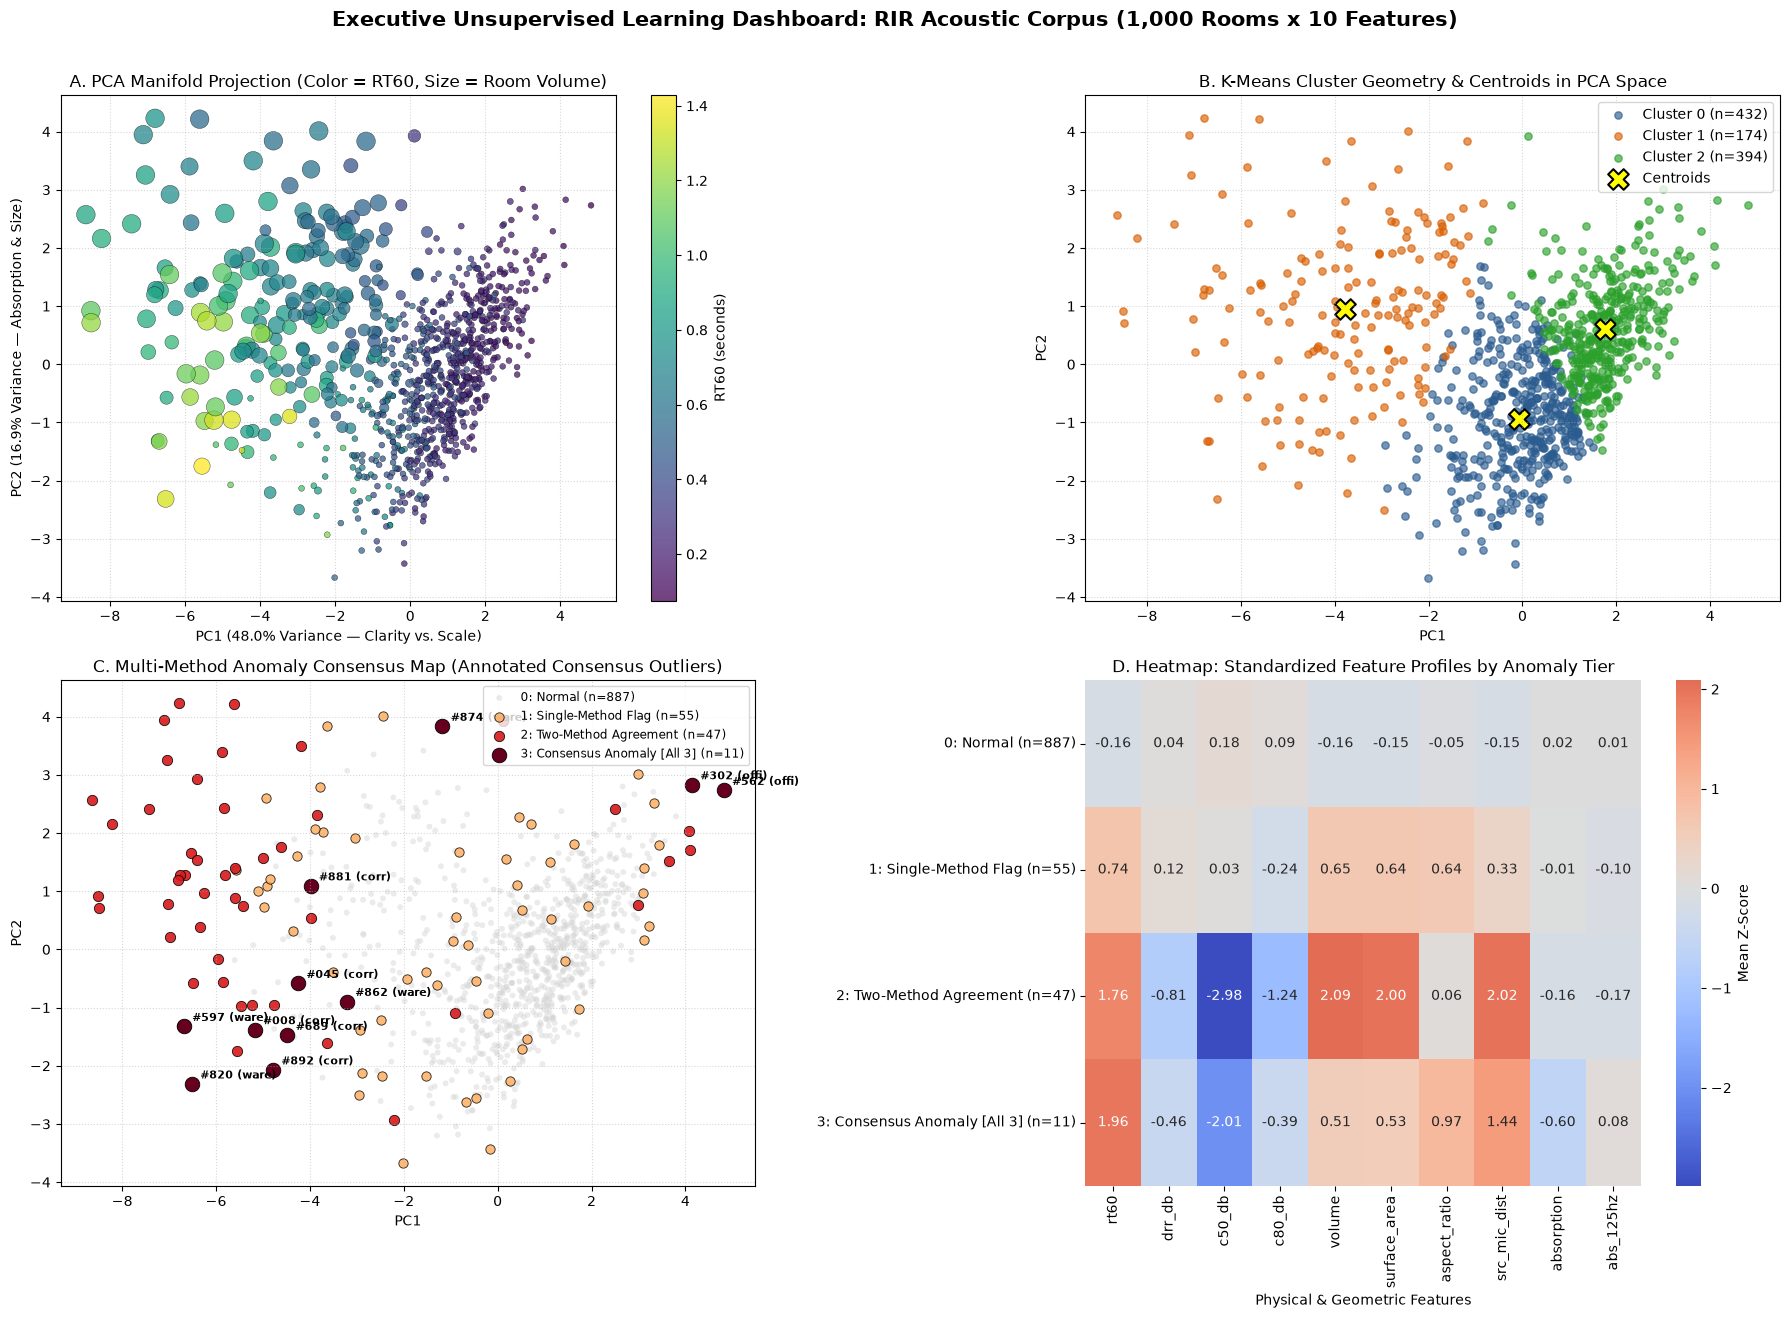

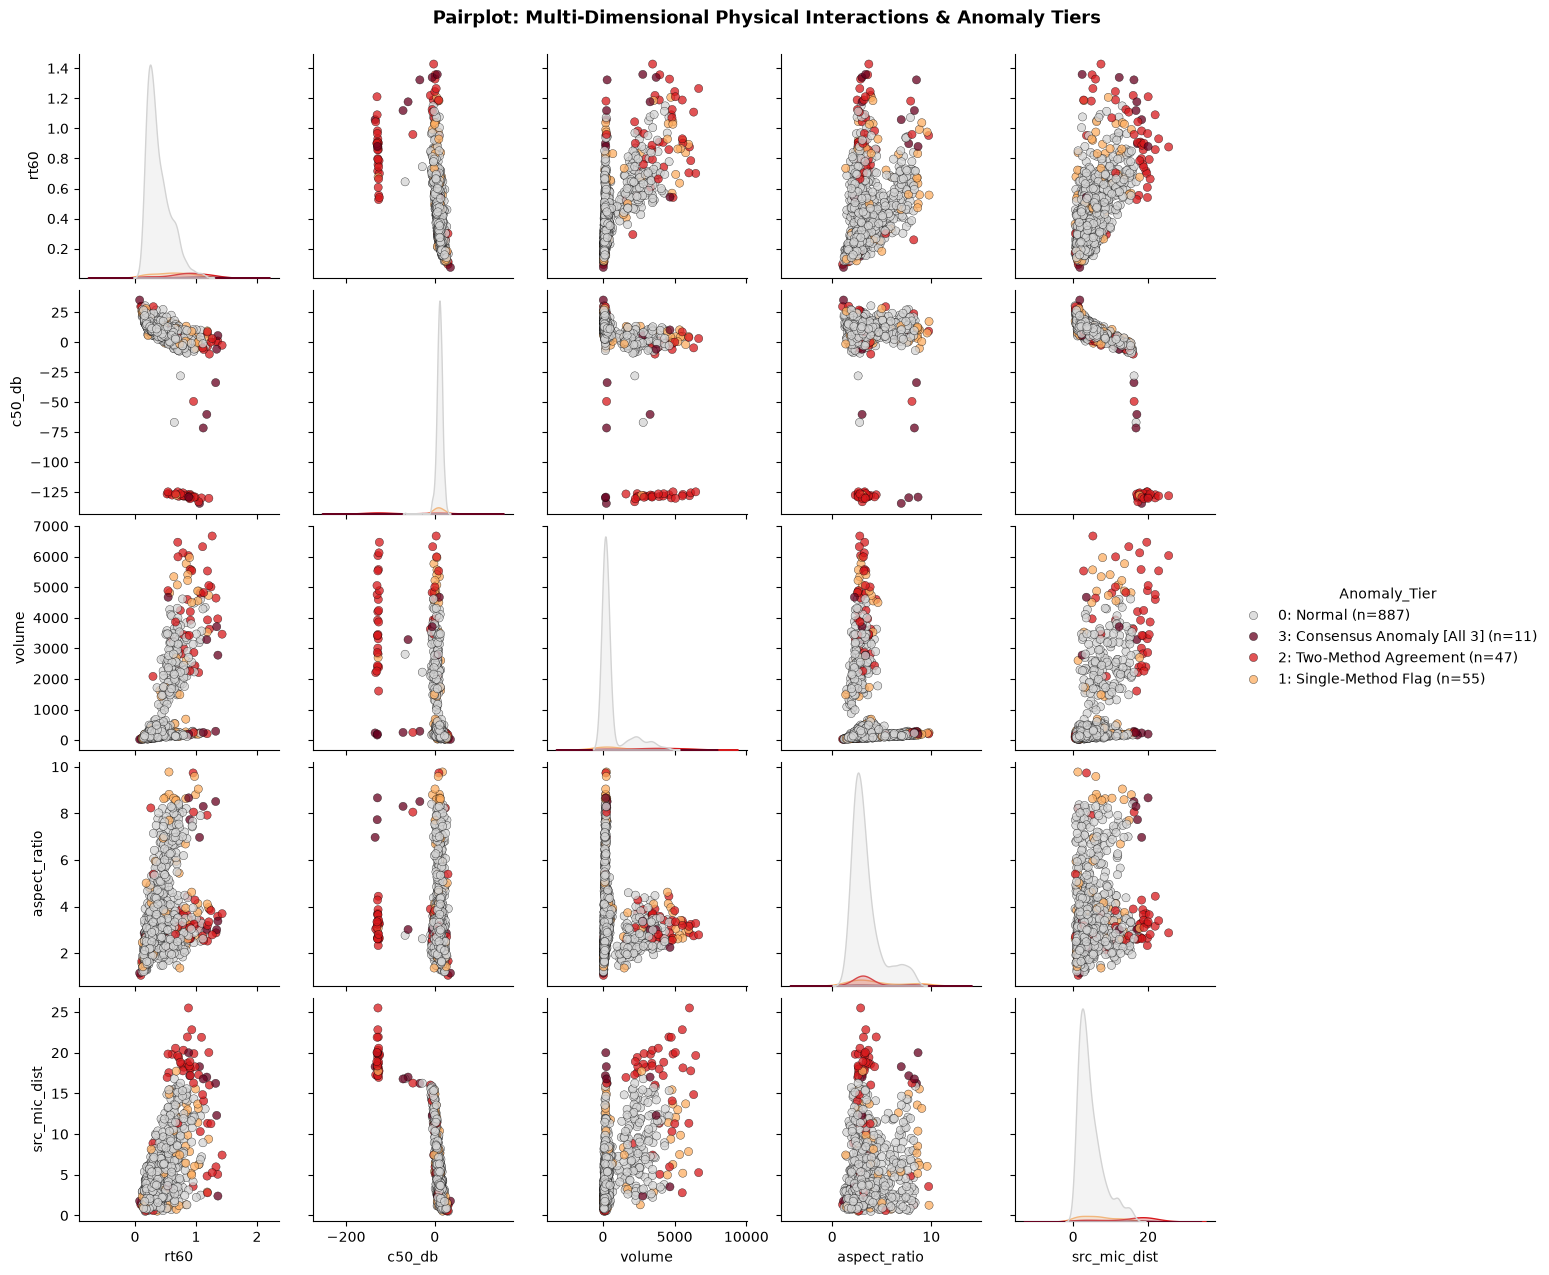

In [37]:
# --- SECTION 8: FINAL VISUALIZATION DASHBOARD (BONUS) ---
# 1. Construct Consensus Anomaly Tier & Anomaly Score Summary
df_dashboard = df_num.copy()
df_dashboard['PC1'] = X_pca[:, 0]
df_dashboard['PC2'] = X_pca[:, 1]
df_dashboard['PC3'] = X_pca[:, 2]
df_dashboard['KMeans_Cluster'] = [f"Cluster {c}" for c in kmeans_labels]
df_dashboard['Room_Family'] = df.loc[df_num.index, 'family'].values

# Count how many anomaly detection methods flagged each room (0, 1, 2, or 3)
vote_count = z_anomalies.astype(int) + iso_anomalies.astype(int) + lof_anomalies.astype(int)
tier_map = {
    0: '0: Normal (n=887)',
    1: '1: Single-Method Flag (n=55)',
    2: '2: Two-Method Agreement (n=47)',
    3: '3: Consensus Anomaly [All 3] (n=11)'
}
df_dashboard['Anomaly_Tier'] = [tier_map[v] for v in vote_count]

# 2. Multi-Panel Executive Dashboard (PCA, Clusters, Anomaly Tiers, and Cluster Profile Heatmap)
fig, axes = plt.subplots(2, 2, figsize=(18, 13))
fig.suptitle("Executive Unsupervised Learning Dashboard: RIR Acoustic Corpus (1,000 Rooms x 10 Features)", 
             fontsize=15, fontweight='bold', y=1.01)

# Panel A: 2D PCA Projection Colored by Physical Reverberation (RT60) & Sized by Volume
sc1 = axes[0, 0].scatter(
    df_dashboard['PC1'], df_dashboard['PC2'],
    c=df_dashboard['rt60'], s=np.clip(df_dashboard['volume'] / 25, 18, 180),
    cmap='viridis', alpha=0.75, edgecolors='k', linewidth=0.3
)
axes[0, 0].set_title("A. PCA Manifold Projection (Color = RT60, Size = Room Volume)")
axes[0, 0].set_xlabel(f"PC1 ({explained_variance[0]*100:.1f}% Variance — Clarity vs. Scale)")
axes[0, 0].set_ylabel(f"PC2 ({explained_variance[1]*100:.1f}% Variance — Absorption & Size)")
plt.colorbar(sc1, ax=axes[0, 0], label="RT60 (seconds)")
axes[0, 0].grid(True, linestyle=':', alpha=0.5)

# Panel B: K-Means Cluster Partitioning with Centroids on PCA Space
cluster_palette = {'Cluster 0': '#2b5c8f', 'Cluster 1': '#d95f02', 'Cluster 2': '#2ca02c'}
for cname, group in df_dashboard.groupby('KMeans_Cluster'):
    axes[0, 1].scatter(group['PC1'], group['PC2'], label=f"{cname} (n={len(group)})",
                       c=cluster_palette[cname], alpha=0.65, s=28)
centroids_pca = pca.transform(kmeans.cluster_centers_)
axes[0, 1].scatter(centroids_pca[:, 0], centroids_pca[:, 1], c='yellow', edgecolors='black',
                   marker='X', s=220, linewidths=1.5, label='Centroids')
axes[0, 1].set_title("B. K-Means Cluster Geometry & Centroids in PCA Space")
axes[0, 1].set_xlabel("PC1")
axes[0, 1].set_ylabel("PC2")
axes[0, 1].legend(loc='upper right')
axes[0, 1].grid(True, linestyle=':', alpha=0.5)

# Panel C: Interactive-Style Anomaly Agreement Map with Annotated Consensus Room IDs
tier_colors = {
    '0: Normal (n=887)': ('#d3d3d3', 18, 0.45),
    '1: Single-Method Flag (n=55)': ('#fdae61', 45, 0.85),
    '2: Two-Method Agreement (n=47)': ('#d7191c', 55, 0.90),
    '3: Consensus Anomaly [All 3] (n=11)': ('#67001f', 110, 1.0)
}
for tier_label, (col, sz, alph) in tier_colors.items():
    sub = df_dashboard[df_dashboard['Anomaly_Tier'] == tier_label]
    axes[1, 0].scatter(sub['PC1'], sub['PC2'], c=col, s=sz, alpha=alph,
                       edgecolors='black' if '0:' not in tier_label else 'none',
                       linewidth=0.6, label=tier_label)

# Annotate the 11 Consensus Anomalies with their Room ID & Family
consensus_rows = df_dashboard[vote_count == 3]
for idx, row in consensus_rows.iterrows():
    room_id = df.loc[idx, 'id'].replace('rir_000', '#')
    axes[1, 0].annotate(f"{room_id} ({row['Room_Family'][:4]})",
                        (row['PC1'], row['PC2']),
                        xytext=(6, 4), textcoords='offset points', fontsize=8, fontweight='bold')
axes[1, 0].set_title("C. Multi-Method Anomaly Consensus Map (Annotated Consensus Outliers)")
axes[1, 0].set_xlabel("PC1")
axes[1, 0].set_ylabel("PC2")
axes[1, 0].legend(loc='upper right', fontsize=8.5)
axes[1, 0].grid(True, linestyle=':', alpha=0.5)

# Panel D: Standardized Feature Heatmap Across Anomaly Agreement Tiers
tier_means = pd.DataFrame(X_scaled, columns=numeric_features, index=df_num.index)
tier_means['Anomaly_Tier'] = df_dashboard['Anomaly_Tier']
heatmap_data = tier_means.groupby('Anomaly_Tier')[numeric_features].mean()
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap='coolwarm', center=0, ax=axes[1, 1], cbar_kws={'label': 'Mean Z-Score'})
axes[1, 1].set_title("D. Heatmap: Standardized Feature Profiles by Anomaly Tier")
axes[1, 1].set_xlabel("Physical & Geometric Features")
axes[1, 1].set_ylabel("")

plt.tight_layout()
plt.show()

# 3. Pairplot of Key Orthogonal Physical Features Colored by Anomaly Agreement Tier
pairplot_features = ['rt60', 'c50_db', 'volume', 'aspect_ratio', 'src_mic_dist']
g = sns.pairplot(
    df_dashboard[pairplot_features + ['Anomaly_Tier']],
    hue='Anomaly_Tier',
    palette={k: v[0] for k, v in tier_colors.items()},
    diag_kind='kde',
    plot_kws={'alpha': 0.75, 's': 35, 'edgecolor': 'k', 'linewidth': 0.3}
)
g.fig.suptitle("Pairplot: Multi-Dimensional Physical Interactions & Anomaly Tiers", y=1.02, fontsize=13, fontweight='bold')
plt.show()

### 8.1 Dashboard Synthesis & Key Takeaways

* **Manifold & Cluster Alignment (Panels A & B):** Panel A visually confirms that room acoustics form a continuous physical manifold where `PC1` (48.0% variance) tracks reverberation time (`rt60`) and room scale (`volume`), while `PC2` (16.9% variance) tracks boundary absorption and room size. Panel B illustrates how centroid-based K-Means partitions this continuous gradient into three adjacent zones (`Cluster 0`: $n=432$, `Cluster 2`: $n=394$, `Cluster 1`: $n=174$).
* **Anomaly Consensus & Feature Signatures (Panels C & D):** Panel C maps the spatial divergence between global boundary outliers (`2: Two-Method Agreement`, $n=47$, concentrated on the left periphery) and internal neighborhood outliers (`1: Single-Method Flag`, $n=55$, driven by LOF inside the core cloud), while pinpointing the 11 annotated **Consensus Anomalies** (`#008`, `#045`, `#302`, `#562`, `#597`, `#689`, `#820`, `#862`, `#874`, `#881`, `#892`). Panel D's heatmap reveals the distinct physical signatures of each tier:
  * **Two-Method Agreement ($n=47$):** Dominated by massive enclosure scale (`volume`: $+2.09\sigma$, `surface_area`: $+2.00\sigma$, `src_mic_dist`: $+2.02\sigma$, `rt60`: $+1.76\sigma$) and severe speech clarity drop-offs (`c50_db`: $-2.98\sigma$, `c80_db`: $-1.24\sigma$).
  * **Consensus Anomalies [All 3] ($n=11$):** Characterized by extreme reverberation (`rt60`: $+1.96\sigma$), large source-to-microphone distances (`src_mic_dist`: $+1.44\sigma$), severe speech clarity collapse (`c50_db`: $-2.01\sigma$), high corridor elongation (`aspect_ratio`: $+0.97\sigma$), and low boundary damping (`absorption`: $-0.60\sigma$).
* **Non-Linear Pairplot Interactions:** The 5-feature pairplot demonstrates why univariate thresholds are insufficient: consensus anomalies (dark burgundy) and two-method outliers (red) separate cleanly only when viewing joint non-linear interactions—such as the sharp cliff in `c50_db` (plunging to $-134\text{ dB}$) once `src_mic_dist` exceeds $16\text{ m}$, or the L-shaped bifurcation between `volume` and `aspect_ratio` that separates cavernous warehouses from narrow, elongated corridors.